# Matching of control group

Notebook purpose:
- Apply PSM 1:10 to match two seperate control groups for battery and ipcei firms
- Compare different matching specifications
- Plot descriptives of resulting control vs. treatment group

#### 1. Set-up

In [1]:
import pandas as pd
from matplotlib.lines import Line2D
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

In [2]:
plt.style.use("default")
#mpl.rcParams.update(mpl.rcParamsDefault)

In [3]:
from ipcei_spillovers.io import data_path, results_path, load_df, save_df, save_fig
from ipcei_spillovers.plotting import COLORS, style_ax
from ipcei_spillovers.matching import propensity_score_match

In [4]:
# ============================================================
# Load data
# ============================================================

firm_master_ipcei = load_df(
    "interim", "combined", "firm_master_ipcei_corrected_extended_jan26.csv", low_memory=False
)
partnership_master_ipcei = load_df(
    "interim", "combined", "partnership_master_ipcei_jan26.csv", low_memory=False
)
firm_month_outcomes = load_df(
    "interim", "combined", "firm_month_outcomes_extended_jan26.csv", low_memory=False
)
print(f"firm_month_outcomes: {firm_month_outcomes.shape}")
print(f"firm_master_ipcei: {firm_master_ipcei.shape}")
print(f"partnership_master_ipcei: {partnership_master_ipcei.shape}")

firm_month_outcomes: (986263, 12)
firm_master_ipcei: (239782, 184)
partnership_master_ipcei: (3943633, 74)


#### 2. Matching

In [5]:
# ============================================================
# PSM Matching - Multiple Specifications with Comparison
# ============================================================

# ============================================================
# Step 1: Prepare data
# ============================================================

fm = firm_master_ipcei.copy()

fm["first_ipcei_date"] = pd.to_datetime(fm["first_ipcei_date"], errors="coerce")
fm["first_ipcei_year"] = fm["first_ipcei_date"].dt.year

# Remove battery round 1 from treated (later, they will also be excluded from controls)
battery_round1 = (
    fm["ipcei_types"].astype(str).str.lower().str.contains("battery", na=False) &
    (fm["first_ipcei_year"] < 2020)
)
fm = fm[~battery_round1].copy()

fm["battery_ipcei"] = fm["ipcei_types"].astype(str).str.lower().str.contains("battery", na=False).astype(int)
fm["hydrogen_ipcei"] = fm["ipcei_types"].astype(str).str.lower().str.contains("hydrogen", na=False).astype(int)

print("\nTreatment groups:")
print(f"  Battery IPCEI: {int(fm['battery_ipcei'].sum())}")
print(f"  Hydrogen IPCEI: {int(fm['hydrogen_ipcei'].sum())}")
print(f"  Potential controls (treated_any==0): {int((fm['treated_any'] == 0).sum())}")

# ============================================================
# Step 2: Define matching specification (treatment-specific)
# ============================================================

# --- Choose baseline years for centrality ---
# Battery baseline: 2020
# Hydrogen baseline: 2021
batt_centrality = "degree_centrality_2020"
hydro_centrality = "degree_centrality_2020" # or change to 2021

# --- Core covariates (shared) ---
base_continuous = ["log_staffCount", "age"]
exact_match_vars = ["nace1_psm", "has_eu_operation"]

# --- Treatment-specific collaboration baseline ---
battery_continuous_vars = base_continuous + ["log_collab_count_2020"]
hydrogen_continuous_vars = base_continuous + ["log_collab_count_2020"] # or change to 2021

# --- Include centrality if not too collinear ---
def should_include_centrality(df, collab_var, cent_var, thresh=0.75):
    cols = [collab_var, cent_var]
    if any(c not in df.columns for c in cols):
        print(f"⚠️ Missing in df: {[c for c in cols if c not in df.columns]}; centrality OFF")
        return False
    corr = df[cols].corr().iloc[0, 1]
    print(f"Corr({collab_var}, {cent_var}) = {corr:.3f}")
    return abs(corr) <= thresh

print("\n" + "=" * 60)
print("MULTICOLLINEARITY CHECK (treatment-specific)")
print("=" * 60)

include_batt_cent = should_include_centrality(
    fm, "log_collab_pretreat_battery", batt_centrality
)
include_hydro_cent = should_include_centrality(
    fm, "log_collab_pretreat_hydrogen", hydro_centrality
)

if include_batt_cent:
    battery_continuous_vars.append(batt_centrality)
if include_hydro_cent:
    hydrogen_continuous_vars.append(hydro_centrality)

print("\n" + "=" * 60)
print("MATCHING SPECIFICATION")
print("=" * 60)
print(f"Battery continuous covariates:  {battery_continuous_vars}")
print(f"Hydrogen continuous covariates: {hydrogen_continuous_vars}")
print(f"Exact matching: {exact_match_vars}")


# ============================================================
# Step 3: Battery Matching - Test Multiple Ratios
# ============================================================

print("\n" + "=" * 60)
print("BATTERY IPCEI MATCHING")
print("=" * 60)

battery_results = {}

for ratio in [3, 5, 7]:
    print(f"\nTesting Battery matching: 1:{ratio}")

    matched, diagnostics = propensity_score_match(
        data=fm,
        treatment_var="battery_ipcei",
        continuous_vars=battery_continuous_vars,
        exact_match_vars=exact_match_vars,
        ratio=ratio,
        caliper=0.2,
        exclude_other_treated=True,
        random_state=42,
    )

    if matched is not None and diagnostics is not None:
        max_smd = max(abs(v) for v in diagnostics.values())
        key = f"battery_1to{ratio}"

        battery_results[key] = {
            "data": matched,
            "diagnostics": diagnostics,
            "ratio": ratio,
            "caliper": 0.20,
            "spec": f"caliper=0.2, ratio={ratio}",
            "max_smd": max_smd,
            "n_treated": int((matched["battery_ipcei"] == 1).sum()),
            "n_control": int((matched["battery_ipcei"] == 0).sum()),
            "balanced_010": all(abs(v) < 0.1 for v in diagnostics.values()),
            "balanced_015": all(abs(v) < 0.15 for v in diagnostics.values()),
        }

        print(f"  Treated: {battery_results[key]['n_treated']}")
        print(f"  Controls: {battery_results[key]['n_control']}")
        print(f"  Max SMD: {max_smd:.3f}")
        print(f"  Balanced (<0.10): {battery_results[key]['balanced_010']}")

# ============================================================
# Step 4: Hydrogen Matching - Test Multiple Specifications
# ============================================================

print("\n" + "=" * 60)
print("HYDROGEN IPCEI MATCHING")
print("=" * 60)

hydrogen_results = {}

specs_to_test = [
    (0.20, 2, "tight, smallest"),
    (0.20, 3, "tight, small"),
    (0.20, 5, "tight, standard"),
    (0.25, 3, "wide, small"),
    (0.25, 5, "wide, standard"),
]

for caliper, ratio, desc in specs_to_test:
    print(f"\nTesting Hydrogen matching: caliper={caliper}, ratio=1:{ratio} ({desc})")

    matched, diagnostics = propensity_score_match(
        data=fm,
        treatment_var="hydrogen_ipcei",
        continuous_vars=hydrogen_continuous_vars,
        exact_match_vars=exact_match_vars,
        ratio=ratio,
        caliper=caliper,
        exclude_other_treated=True,
        random_state=42,
    )

    if matched is not None and diagnostics is not None:
        max_smd = max(abs(v) for v in diagnostics.values())
        key = f"hydrogen_cal{int(caliper * 100)}_r{ratio}"

        hydrogen_results[key] = {
            "data": matched,
            "diagnostics": diagnostics,
            "ratio": ratio,
            "caliper": float(caliper),
            "spec": f"caliper={caliper}, ratio={ratio}",
            "desc": desc,
            "max_smd": max_smd,
            "n_treated": int((matched["hydrogen_ipcei"] == 1).sum()),
            "n_control": int((matched["hydrogen_ipcei"] == 0).sum()),
            "balanced_010": all(abs(v) < 0.1 for v in diagnostics.values()),
            "balanced_015": all(abs(v) < 0.15 for v in diagnostics.values()),
        }

        print(f"  Treated: {hydrogen_results[key]['n_treated']}")
        print(f"  Controls: {hydrogen_results[key]['n_control']}")
        print(f"  Max SMD: {max_smd:.3f}")
        print(f"  Balanced (<0.15): {hydrogen_results[key]['balanced_015']}")

# ============================================================
# Step 5: CREATE COMPARISON TABLE
# ============================================================

print("\n" + "=" * 60)
print("COMPARISON TABLE - ALL SPECIFICATIONS")
print("=" * 60)

comparison_data = []

for key, result in battery_results.items():
    comparison_data.append({
        "Treatment": "Battery",
        "Spec_Key": key,
        "Caliper": 0.20,
        "Ratio": result["ratio"],
        "Specification": result["spec"],
        "N_Treated": result["n_treated"],
        "N_Control": result["n_control"],
        "N_Total": result["n_treated"] + result["n_control"],
        "Max_SMD": result["max_smd"],
        "Balanced_0.10": bool(result["balanced_010"]),
        "Balanced_0.15": bool(result["balanced_015"]),
    })

for key, result in hydrogen_results.items():
    comparison_data.append({
        "Treatment": "Hydrogen",
        "Spec_Key": key,
        "Caliper": result["caliper"],
        "Ratio": result["ratio"],
        "Specification": result["spec"],
        "N_Treated": result["n_treated"],
        "N_Control": result["n_control"],
        "N_Total": result["n_treated"] + result["n_control"],
        "Max_SMD": result["max_smd"],
        "Balanced_0.10": bool(result["balanced_010"]),
        "Balanced_0.15": bool(result["balanced_015"]),
    })

comparison_df = pd.DataFrame(comparison_data)
comparison_df = comparison_df.sort_values(["Treatment", "Caliper", "Ratio"])

print("\n")
print(comparison_df.to_string(index=False))

# Save comparison table
save_df(comparison_df, "processed", "combined", "matching_specifications_all.csv")

print("\nComparison table saved - review to select specifications manually")

# ============================================================
# Step 6: Print detailed balance for ALL specs
# ============================================================

print("\n" + "=" * 60)
print("DETAILED BALANCE - ALL SPECIFICATIONS")
print("=" * 60)

for treatment in ["Battery", "Hydrogen"]:
    results_dict = battery_results if treatment == "Battery" else hydrogen_results

    for key, result in results_dict.items():
        print(f"\n{treatment} - {key}:")
        print("-" * 40)
        for var, smd in result["diagnostics"].items():
            status = "✅" if abs(smd) < 0.10 else "⚠️" if abs(smd) < 0.15 else "❌"
            print(f"  {status} {var:25s}: {smd:6.3f}")

print("\nAll specifications run - ready for manual selection")

/var/folders/1w/t9ryrq_57m77f4wzbw78745m044mx9/T/ipykernel_65543/1383902386.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  fm["first_ipcei_date"] = pd.to_datetime(fm["first_ipcei_date"], errors="coerce")



Treatment groups:
  Battery IPCEI: 30
  Hydrogen IPCEI: 107
  Potential controls (treated_any==0): 239632

MULTICOLLINEARITY CHECK (treatment-specific)
Corr(log_collab_pretreat_battery, degree_centrality_2020) = 0.664
Corr(log_collab_pretreat_hydrogen, degree_centrality_2020) = 0.475

MATCHING SPECIFICATION
Battery continuous covariates:  ['log_staffCount', 'age', 'log_collab_count_2020', 'degree_centrality_2020']
Hydrogen continuous covariates: ['log_staffCount', 'age', 'log_collab_count_2020', 'degree_centrality_2020']
Exact matching: ['nace1_psm', 'has_eu_operation']

BATTERY IPCEI MATCHING

Testing Battery matching: 1:3
  Treated: 28
  Controls: 84
  Max SMD: 0.220
  Balanced (<0.10): False

Testing Battery matching: 1:5
  Treated: 28
  Controls: 140
  Max SMD: 0.106
  Balanced (<0.10): False

Testing Battery matching: 1:7
  Treated: 28
  Controls: 196
  Max SMD: 0.113
  Balanced (<0.10): False

HYDROGEN IPCEI MATCHING

Testing Hydrogen matching: caliper=0.2, ratio=1:2 (tight, sma

In [7]:
# ============================================================
# Inspect control firms
# ============================================================

def inspect_controls(spec_key, results_dict, treatment_var, top_n=20):
    matched = results_dict[spec_key]["data"].copy()

    controls = matched[matched[treatment_var] == 0][[
        "Linkedin_name", "matched_to", "nace1_psm", "nace1_proxy",
        "nace2_industry", "log_staffCount", "age",
        "log_collab_count_2020", "degree_centrality_2020"
    ]].copy()

    print(f"\n{'='*60}")
    print(f"Control firms: {spec_key}")
    print(f"Total controls: {len(controls)}")
    print(f"{'='*60}")

    print("\nnace1_psm distribution:")
    print(controls["nace1_psm"].value_counts())

    print("\nnace2_industry distribution:")
    print(controls["nace2_industry"].value_counts(dropna=False))

    print(f"\nSample of control firms (first {top_n}):")
    print(controls.head(top_n).to_string())

    return controls

# Battery specs
battery_controls_s1 = inspect_controls(
    "battery_1to5", battery_results, "battery_ipcei"
)
battery_controls_s2 = inspect_controls(
    "battery_1to7", battery_results, "battery_ipcei"
)

# Hydrogen specs
hydrogen_controls_s1 = inspect_controls(
    "hydrogen_cal20_r2", hydrogen_results, "hydrogen_ipcei"
)
hydrogen_controls_s2 = inspect_controls(
    "hydrogen_cal25_r3", hydrogen_results, "hydrogen_ipcei"
)

# Check for any specific suspicious firms
suspicious = ["bosch", "bosch-oesterreich", "solarfoods", "luxcara",
              "hybritdevelopment", "rostock-port"]

for label, controls in [
    ("Battery S1", battery_controls_s1),
    ("Battery S2", battery_controls_s2),
    ("Hydrogen S1", hydrogen_controls_s1),
    ("Hydrogen S2", hydrogen_controls_s2)
]:
    found = controls[
        controls["Linkedin_name"].str.lower().isin(suspicious)
    ]
    if len(found) > 0:
        print(f"\n⚠️  Suspicious firms in {label}:")
        print(found[["Linkedin_name", "nace1_psm", "matched_to"]].to_string())
    else:
        print(f"✓ No suspicious firms in {label}")


Control firms: battery_1to5
Total controls: 140

nace1_psm distribution:
nace1_psm
Production           125
Knowledge economy     10
Energy system          5
Name: count, dtype: int64

nace2_industry distribution:
nace2_industry
NaN                                 54
26 — Electronics Manufacturing      25
28 — Machinery Manufacturing        19
29 — Motor Vehicle Manufacturing    12
62 — IT Services                     9
20 — Chemical Manufacturing          5
38 — Environmental Services          4
07 — Mining                          3
35 — Utilities                       3
06 — Oil and Gas                     3
49 — Land Transport                  2
72 — Research Services               1
Name: count, dtype: int64

Sample of control firms (first 20):
                            Linkedin_name  matched_to   nace1_psm        nace1_proxy                    nace2_industry  log_staffCount    age  log_collab_count_2020  degree_centrality_2020
209508                             tenova       16

In [7]:
# ============================================================
# Save Selected Control Group Specifications
# ============================================================

print("\n" + "=" * 60)
print("SAVING MATCHED SAMPLES & CREATING PANELS")
print("=" * 60)

# ============================================================
# Step 1: Manual Specification Selection
# ============================================================

# Battery
BATTERY_SPEC_1 = "battery_1to5"  # Balance (SMD=0.106)
BATTERY_SPEC_2 = "battery_1to7"  # Power (SMD=0.113) ← PRIMARY

# Hydrogen
HYDROGEN_SPEC_1 = "hydrogen_cal20_r2"   # Balance (SMD=0.066)
HYDROGEN_SPEC_2 = "hydrogen_cal25_r3"   # Power (SMD=0.097) ← PRIMARY

print("\nSelected specifications:")
print(f"  Battery Spec 1 (balance): {BATTERY_SPEC_1}")
print(f"  Battery Spec 2 (power):   {BATTERY_SPEC_2}")
print(f"  Hydrogen Spec 1 (balance): {HYDROGEN_SPEC_1}")
print(f"  Hydrogen Spec 2 (power):   {HYDROGEN_SPEC_2}")

# ============================================================
# Step 2: Load firm_month_outcomes
# ============================================================

# Convert month to datetime
firm_month_outcomes["month"] = pd.to_datetime(firm_month_outcomes["month"], errors="coerce")
for col in ["n_collabs", "n_collabs_hydrogen", "n_collabs_battery",
        "n_collabs_eu", "n_collabs_non_eu", "n_collabs_eu_primary",
        "n_collabs_eu_crossborder", "n_collabs_domestic",
        "n_collabs_crosssector", "n_collabs_withinsector"]:
    if col in firm_month_outcomes.columns:
        firm_month_outcomes[col] = pd.to_numeric(
            firm_month_outcomes[col], errors="coerce"
        ).fillna(0).astype(int)

print(f"\nFirm-month outcomes: {len(firm_month_outcomes)} rows, {firm_month_outcomes['Linkedin_name'].nunique()} firms")

# ============================================================
# Step 3: Verify treatment dates exist
# ============================================================

print(f"Battery treatment dates available: "
      f"{firm_master_ipcei['first_battery_date'].notna().sum()} firms")
print(f"Hydrogen treatment dates available: "
      f"{firm_master_ipcei['first_hydrogen_date'].notna().sum()} firms")

# ============================================================
# Step 4: Build and save panels for each specification
# ============================================================

def build_and_save_panels(spec_key, results_dict, tech_label, spec_number, treatment_var, date_col):
    """
    Build matched panels from firm_month_outcomes for one specification.

    Creates:
    1. Matched firms list (cross-sectional)
    2. C&S-ready panel (firm-month with treatment info)
    3. Plot panel (event-time structure for visualization)
    """

    print(f"\n{'='*60}")
    print(f"Building {tech_label.upper()} Spec {spec_number} panels")
    print(f"{'='*60}")

    # Get matched sample
    matched_firms = results_dict[spec_key]["data"].copy()

    # Add indicators
    matched_firms["is_treated"] = (matched_firms[treatment_var] == 1).astype(int)
    matched_firms["is_control"] = (matched_firms[treatment_var] == 0).astype(int)
    matched_firms["spec_key"] = spec_key
    matched_firms["spec_number"] = spec_number

    # Save matched firms list
    save_df(matched_firms, "processed", "combined", f"{tech_label}_spec{spec_number}_matched_firms.csv")

    # Get list of matched firm names
    matched_names = set(matched_firms["Linkedin_name"])

    # Create lookup table (firm characteristics)
    lookup = matched_firms[[
        "Linkedin_name", "is_treated", "is_control", "matched_to",
        "nace1_psm", "nace1_proxy", "firm_type", "log_staffCount", "age", "has_eu_operation",
        "log_collab_count_2020", "degree_centrality_2020"
    ]].drop_duplicates(subset=["Linkedin_name"]).copy()   # ← add this

    # ============================================================
    # Create C&S-ready panel
    # ============================================================

    panel_sparse = firm_month_outcomes[firm_month_outcomes["Linkedin_name"].isin(matched_names)].copy()

    # Zero-fill: create complete firm × month grid
    # Define panel window: 2020-01 to 2025-12
    all_months = pd.date_range("2020-01-01", "2025-12-01", freq="MS")
    all_firms  = list(matched_names)

    full_grid = pd.MultiIndex.from_product(
        [all_firms, all_months],
        names=["Linkedin_name", "month"]
    ).to_frame(index=False)

    panel = full_grid.merge(panel_sparse, on=["Linkedin_name", "month"], how="left")
    for col in ["n_collabs", "n_collabs_hydrogen", "n_collabs_battery",
            "n_collabs_eu", "n_collabs_non_eu", "n_collabs_eu_primary",
            "n_collabs_eu_crossborder", "n_collabs_domestic",
            "n_collabs_crosssector", "n_collabs_withinsector"]:
        panel[col] = panel[col].fillna(0).astype(int)

    panel = panel.merge(lookup, on="Linkedin_name", how="left")

    # Add treatment timing (technology-specific date)
    _treatment_dates = firm_master_ipcei[["Linkedin_name", date_col]].copy()
    _treatment_dates[date_col] = pd.to_datetime(
        _treatment_dates[date_col], errors="coerce"
    )
    _treatment_dates["g"] = (
        _treatment_dates[date_col]
        .dt.to_period("M")
        .dt.to_timestamp()
    )

    panel = panel.merge(
        _treatment_dates[["Linkedin_name", "g"]],
        on="Linkedin_name",
        how="left"
    )

    # For controls, g should be NA or 0
    panel.loc[panel["is_control"] == 1, "g"] = pd.NaT

    # Calculate event time (months since treatment)
    panel["month_period"] = panel["month"].dt.to_period("M")
    panel["g_period"] = panel["g"].dt.to_period("M")

    # Event time in months
    panel["event_time"] = (panel["month_period"] - panel["g_period"]).apply(
        lambda x: x.n if pd.notna(x) else np.nan
    )

    # Post-event indicator
    panel["post_event"] = (panel["event_time"] >= 0).astype(int)
    panel.loc[panel["event_time"].isna(), "post_event"] = 0

    # Select variables for C&S
    cs_panel = panel[[
        "Linkedin_name", "month", "g", "event_time", "post_event",
        "is_treated", "is_control", "matched_to",
        "n_collabs", "n_collabs_hydrogen", "n_collabs_battery",
        "n_collabs_eu", "n_collabs_non_eu", "n_collabs_eu_primary",
        "n_collabs_eu_crossborder", "n_collabs_domestic",
        "n_collabs_crosssector", "n_collabs_withinsector",
        "nace1_psm", "nace1_proxy", "firm_type", "log_staffCount", "age",
        "log_collab_count_2020", "degree_centrality_2020"
    ]].copy()

    cs_panel = cs_panel.drop_duplicates(
        subset=["Linkedin_name", "month"]
    ).sort_values(["Linkedin_name", "month"])
    save_df(cs_panel, "processed", "combined", f"{tech_label}_spec{spec_number}_cs_ready.csv")

    # ============================================================
    # Create plot panel (event-time aligned)
    # ============================================================

    # For plotting, we want event time relative to treatment
    # Controls aligned to their matched treated firm's treatment date

    # Get treatment dates for treated firms
    treated_g = (
        panel[panel["is_treated"] == 1][["matched_to", "g"]]
        .drop_duplicates(subset=["matched_to"])
    )
    treated_g = treated_g.rename(columns={"matched_to": "Linkedin_name", "g": "g_treated"})

    # For controls, use their matched treated firm's g
    plot_panel = panel.copy()
    plot_panel = plot_panel.merge(
        treated_g.rename(columns={"Linkedin_name": "matched_to", "g_treated": "g_control"}),
        on="matched_to",
        how="left"
    )

    # Use appropriate g for each firm
    plot_panel["g_use"] = np.where(
        plot_panel["is_treated"] == 1,
        plot_panel["g"],
        plot_panel["g_control"]
    )

    # Recalculate event time with aligned g
    plot_panel["g_use_period"] = pd.to_datetime(plot_panel["g_use"], errors="coerce").dt.to_period("M")
    plot_panel["event_time_aligned"] = (
        plot_panel["month_period"] - plot_panel["g_use_period"]
    ).apply(lambda x: x.n if pd.notna(x) else np.nan)

    # Keep only +/- 12 months around treatment
    plot_panel = plot_panel[plot_panel["event_time_aligned"].between(-12, 12)].copy()

    # Select variables for plotting
    plot_panel_out = plot_panel[[
        "Linkedin_name",
        "matched_to",
        "month",
        "event_time_aligned",
        "post_event",
        "is_treated",
        "is_control",
        "n_collabs"
    ]].copy()

    plot_panel_out = plot_panel_out.sort_values(["matched_to", "event_time_aligned"])

    save_df(plot_panel_out, "processed", "combined", f"{tech_label}_spec{spec_number}_plot_panel.csv")

    # Summary
    print(f"\n✅ {tech_label.capitalize()} Spec {spec_number} saved:")
    print(f"   Matched firms: {len(matched_firms)}")
    print(f"     Treated: {matched_firms['is_treated'].sum()}")
    print(f"     Controls: {matched_firms['is_control'].sum()}")
    print(f"   C&S panel: {len(cs_panel)} firm-months")
    print(f"   Plot panel: {len(plot_panel_out)} firm-months (±12 months)")

# ============================================================
# Step 5: Build all panels
# ============================================================

build_and_save_panels(
    BATTERY_SPEC_1, battery_results, "battery", 1,
    "battery_ipcei", "first_battery_date"
)
build_and_save_panels(
    BATTERY_SPEC_2, battery_results, "battery", 2,
    "battery_ipcei", "first_battery_date"
)
build_and_save_panels(
    HYDROGEN_SPEC_1, hydrogen_results, "hydrogen", 1,
    "hydrogen_ipcei", "first_hydrogen_date"
)
build_and_save_panels(
    HYDROGEN_SPEC_2, hydrogen_results, "hydrogen", 2,
    "hydrogen_ipcei", "first_hydrogen_date"
)

print("\n" + "="*60)
print("✅ ALL PANELS SAVED")
print("="*60)
print("\nFiles created for each spec:")
print("  1. {tech}_spec{n}_matched_firms.csv - Matched sample (cross-sectional)")
print("  2. {tech}_spec{n}_cs_ready.csv - C&S DiD panel (firm-months)")
print("  3. {tech}_spec{n}_plot_panel.csv - Plot panel (event-time ±12 months)")
print("\nReady for C&S estimation in R!")


SAVING MATCHED SAMPLES & CREATING PANELS

Selected specifications:
  Battery Spec 1 (balance): battery_1to5
  Battery Spec 2 (power):   battery_1to7
  Hydrogen Spec 1 (balance): hydrogen_cal20_r2
  Hydrogen Spec 2 (power):   hydrogen_cal25_r3

Firm-month outcomes: 986263 rows, 221101 firms
Battery treatment dates available: 239782 firms
Hydrogen treatment dates available: 239782 firms

Building BATTERY Spec 1 panels


/var/folders/1w/t9ryrq_57m77f4wzbw78745m044mx9/T/ipykernel_65543/1271436910.py:120: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  _treatment_dates[date_col] = pd.to_datetime(



✅ Battery Spec 1 saved:
   Matched firms: 168
     Treated: 28
     Controls: 140
   C&S panel: 12096 firm-months
   Plot panel: 4200 firm-months (±12 months)

Building BATTERY Spec 2 panels


/var/folders/1w/t9ryrq_57m77f4wzbw78745m044mx9/T/ipykernel_65543/1271436910.py:120: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  _treatment_dates[date_col] = pd.to_datetime(



✅ Battery Spec 2 saved:
   Matched firms: 224
     Treated: 28
     Controls: 196
   C&S panel: 16128 firm-months
   Plot panel: 5600 firm-months (±12 months)

Building HYDROGEN Spec 1 panels


/var/folders/1w/t9ryrq_57m77f4wzbw78745m044mx9/T/ipykernel_65543/1271436910.py:120: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  _treatment_dates[date_col] = pd.to_datetime(



✅ Hydrogen Spec 1 saved:
   Matched firms: 277
     Treated: 94
     Controls: 183
   C&S panel: 19368 firm-months
   Plot panel: 6725 firm-months (±12 months)

Building HYDROGEN Spec 2 panels


/var/folders/1w/t9ryrq_57m77f4wzbw78745m044mx9/T/ipykernel_65543/1271436910.py:120: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  _treatment_dates[date_col] = pd.to_datetime(



✅ Hydrogen Spec 2 saved:
   Matched firms: 365
     Treated: 94
     Controls: 271
   C&S panel: 25128 firm-months
   Plot panel: 8725 firm-months (±12 months)

✅ ALL PANELS SAVED

Files created for each spec:
  1. {tech}_spec{n}_matched_firms.csv - Matched sample (cross-sectional)
  2. {tech}_spec{n}_cs_ready.csv - C&S DiD panel (firm-months)
  3. {tech}_spec{n}_plot_panel.csv - Plot panel (event-time ±12 months)

Ready for C&S estimation in R!


In [10]:
# Check — are any battery controls also hydrogen IPCEI firms?
battery_controls = battery_results[BATTERY_SPEC_2]["data"]
battery_controls_names = set(
    battery_controls[battery_controls["battery_ipcei"]==0]["Linkedin_name"]
)
hydrogen_treated_names = set(
    firm_master_ipcei[firm_master_ipcei["hydrogen_ipcei"]==1]["Linkedin_name"]
    if "hydrogen_ipcei" in firm_master_ipcei.columns
    else []
)
overlap = battery_controls_names & hydrogen_treated_names
print(f"Battery controls that are Hydrogen IPCEI firms: {len(overlap)}")
print(overlap)

hydrogen_controls_names = set(
    hydrogen_results[HYDROGEN_SPEC_2]["data"]
    [hydrogen_results[HYDROGEN_SPEC_2]["data"]["hydrogen_ipcei"]==0]["Linkedin_name"]
)
battery_treated_names = set(
    firm_master_ipcei[firm_master_ipcei["ipcei_types"].str.lower().str.contains(
        "battery", na=False) &
        (firm_master_ipcei["treated_any"]==1)]["Linkedin_name"]
)
overlap = hydrogen_controls_names & battery_treated_names
print(f"Hydrogen controls that are Battery IPCEI firms: {len(overlap)}")
print(overlap)

Battery controls that are Hydrogen IPCEI firms: 0
set()
Hydrogen controls that are Battery IPCEI firms: 0
set()


#### 3. Diagnostics and visualizations

In [7]:
# ============================================================
# General helper
# ============================================================

def union_vars(*lists):
    out = []
    for L in lists:
        for v in L:
            if v not in out:
                out.append(v)
    return out

# ============================================================
# Variable labels
# ============================================================

VAR_LABELS = {
    "log_staffCount": "Log employees",
    "age": "Firm age (years)",
    "log_collab_count_2020": "Log collaboration count",
    "degree_centrality_2020": "Network centrality (degree)",
}

# ============================================================
# Load matched samples
# ============================================================

# Battery specs
battery_spec1 = load_df("processed", "combined", "battery_spec1_matched_firms.csv")
battery_spec2 = load_df("processed", "combined", "battery_spec2_matched_firms.csv")

# Hydrogen specs
hydrogen_spec1 = load_df("processed", "combined", "hydrogen_spec1_matched_firms.csv")
hydrogen_spec2 = load_df("processed", "combined", "hydrogen_spec2_matched_firms.csv")

# Get diagnostics from results
battery_spec1_diag = battery_results["battery_1to5"]["diagnostics"]
battery_spec2_diag = battery_results["battery_1to7"]["diagnostics"]
hydrogen_spec1_diag = hydrogen_results["hydrogen_cal20_r2"]["diagnostics"]
hydrogen_spec2_diag = hydrogen_results["hydrogen_cal25_r3"]["diagnostics"]

In [16]:
# ============================================================
# Combined Love Plot
# ============================================================

def plot_love_plot_combined(battery_diag, hydrogen_diag, spec_label, filename):

    fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)

    def draw(ax, diagnostics, tech_name, treat_color):

        vars_list = list(diagnostics.keys())
        smds = [diagnostics[v] for v in vars_list]

        colors = []
        for s in smds:
            if abs(s) <= 0.10:
                colors.append(treat_color)
            elif abs(s) <= 0.15:
                colors.append("#FFD700")
            else:
                colors.append("#FFA500")

        ax.barh(
            [VAR_LABELS.get(v, v) for v in vars_list],
            smds,
            color=colors,
            edgecolor="black",
            linewidth=0.4
        )

        ax.axvline(0, color="black", linewidth=0.8)
        ax.axvline(0.10, linestyle="--", color="gray", linewidth=0.9)
        ax.axvline(-0.10, linestyle="--", color="gray", linewidth=0.9)

        ax.set_xlabel("Standardized Mean Difference", fontsize=13)
        ax.tick_params(axis="both", labelsize=13)
        ax.grid(axis="x", alpha=0.25)
        style_ax(ax)

        # --- Dynamic legend ---
        legend_elements = [
            Line2D([0],[0], color=treat_color, lw=6, label=f"{tech_name} ≤ 0.10"),
            Line2D([0],[0], color="#FFD700", lw=6, label="0.10–0.15"),
            Line2D([0],[0], color="#FFA500", lw=6, label="> 0.15"),
        ]

        ax.legend(
            handles=legend_elements,
            frameon=False,
            fontsize=13,
            loc="upper left"
        )

    # Battery = GREEN, Hydrogen = BLUE
    draw(axes[0], battery_diag, "Battery", COLORS["two"][1])
    draw(axes[1], hydrogen_diag, "Hydrogen", COLORS["two"][0])


    plt.tight_layout()
    save_fig(fig, "descriptives_postmatch", filename)
    plt.show()

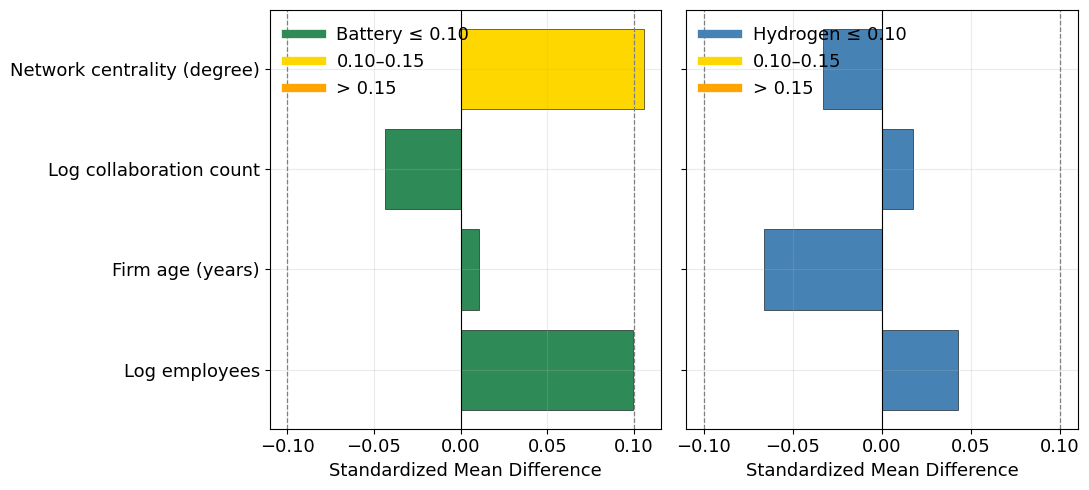

In [17]:
# SPEC 1 - BALANCE

plot_love_plot_combined(
    battery_spec1_diag,
    hydrogen_spec1_diag,
    spec_label="Spec 1 – Balance",
    filename="matching_balance_loveplot_spec1"
)

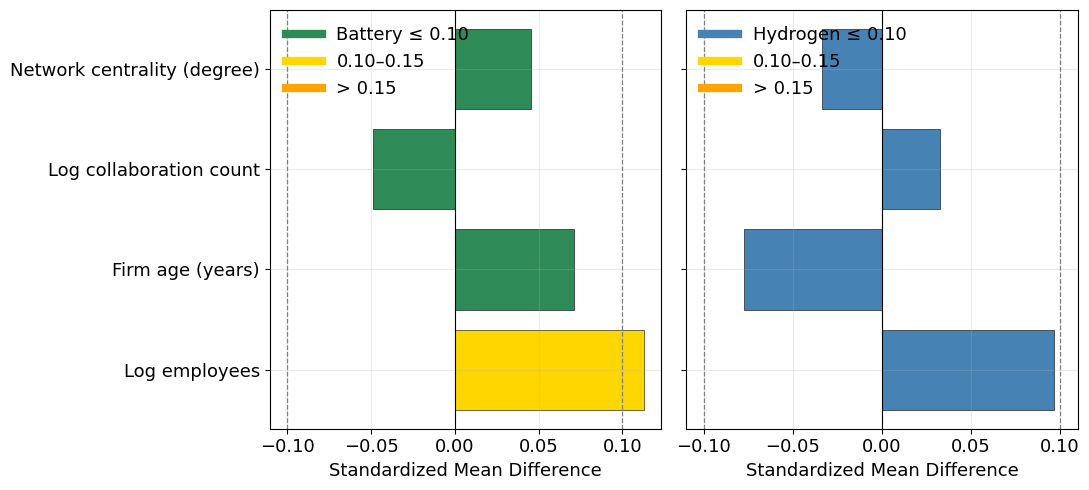

In [18]:
# SPEC 2 - POWER

plot_love_plot_combined(
    battery_spec2_diag,
    hydrogen_spec2_diag,
    spec_label="Spec 2 – Power",
    filename="matching_balance_loveplot_spec2"
)

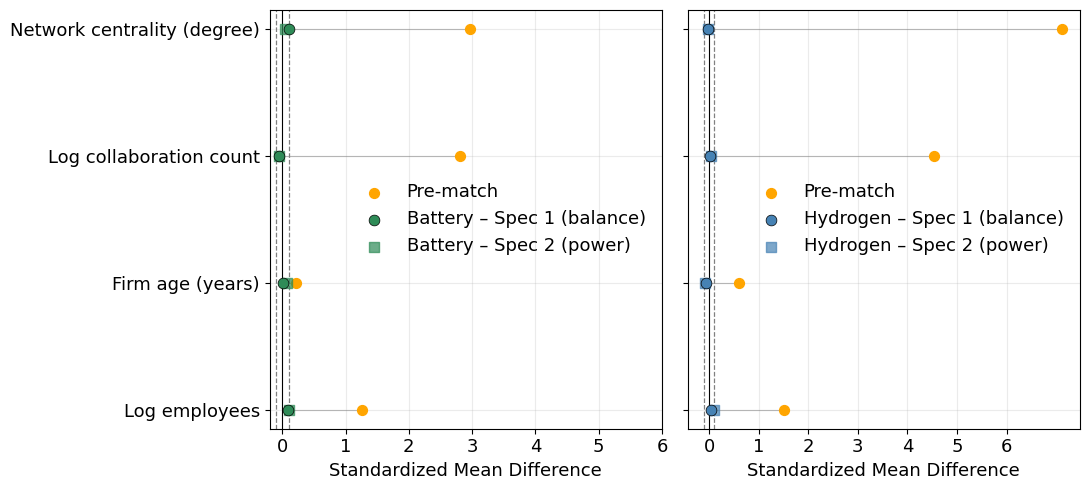

In [19]:
# ============================================================
# 2. Before–After Love Plot
# ============================================================

def plot_love_before_after_both_specs(
    fm,
    battery_s1,
    battery_s2,
    hydrogen_s1,
    hydrogen_s2,
    battery_vars,
    hydrogen_vars
):

    def compute_smd(data, treatment_var, var):
        treated = data[data[treatment_var] == 1][var].dropna()
        control = data[data[treatment_var] == 0][var].dropna()
        pooled_sd = data[var].std()
        return (treated.mean() - control.mean()) / pooled_sd if pooled_sd else 0

    # Create treatment indicators once (in fm)
    fm["is_battery_treated"] = (
        fm["ipcei_types"].astype(str).str.lower().str.contains("battery", na=False)
    ).astype(int)

    fm["is_hydrogen_treated"] = (
        fm["ipcei_types"].astype(str).str.lower().str.contains("hydrogen", na=False)
    ).astype(int)

    # Ensure indicators exist in matched dfs too (so plotting never KeyErrors)
    for df in [battery_s1, battery_s2]:
        df["is_battery_treated"] = (
            df["ipcei_types"].astype(str).str.lower().str.contains("battery", na=False)
        ).astype(int)

    for df in [hydrogen_s1, hydrogen_s2]:
        df["is_hydrogen_treated"] = (
            df["ipcei_types"].astype(str).str.lower().str.contains("hydrogen", na=False)
        ).astype(int)

    fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)

    def draw(ax, s1_df, s2_df, tech_label, treatment_var, treat_color, vars_list):

        vars_list = list(vars_list)
        y = np.arange(len(vars_list))

        before_vals   = [compute_smd(fm,   treatment_var, v) for v in vars_list]
        after_s1_vals = [compute_smd(s1_df, treatment_var, v) for v in vars_list]
        after_s2_vals = [compute_smd(s2_df, treatment_var, v) for v in vars_list]

        # Connecting lines (before → spec1)
        for i in range(len(vars_list)):
            ax.plot(
                [before_vals[i], after_s1_vals[i]],
                [y[i], y[i]],
                color="gray",
                linewidth=0.8,
                alpha=0.5
            )

        # Points
        ax.scatter(before_vals, y,
                   color="#FFA500",
                   label="Pre-match",
                   zorder=3,
                   s=50)

        ax.scatter(after_s1_vals, y,
                   color=treat_color,
                   label=f"{tech_label} – Spec 1 (balance)",
                   zorder=4,
                   s=60,
                   marker='o',
                   edgecolors='black',
                   linewidths=0.5)

        ax.scatter(after_s2_vals, y,
                   color=treat_color,
                   label=f"{tech_label} – Spec 2 (power)",
                   zorder=3,
                   s=45,
                   marker='s',
                   alpha=0.7)

        ax.axvline(0, color="black", linewidth=0.8)
        ax.axvline(0.10, linestyle="--", color="gray", linewidth=0.9)
        ax.axvline(-0.10, linestyle="--", color="gray", linewidth=0.9)
        ax.set_xticks([0, 1, 2, 3, 4, 5, 6])

        ax.set_yticks(y)
        ax.set_yticklabels([VAR_LABELS.get(v, v) for v in vars_list], fontsize=13)

        ax.set_xlabel("Standardized Mean Difference", fontsize=13)
        ax.tick_params(axis="x", labelsize=13)
        ax.grid(axis="x", alpha=0.25)
        style_ax(ax)
        ax.legend(frameon=False, fontsize=13, loc="center right")

    # Battery panel (uses battery_vars)
    draw(
        axes[0],
        battery_s1,
        battery_s2,
        tech_label="Battery",
        treatment_var="is_battery_treated",
        treat_color=COLORS["two"][1],
        vars_list=battery_vars
    )

    # Hydrogen panel (uses hydrogen_vars)
    draw(
        axes[1],
        hydrogen_s1,
        hydrogen_s2,
        tech_label="Hydrogen",
        treatment_var="is_hydrogen_treated",
        treat_color=COLORS["two"][0],
        vars_list=hydrogen_vars
    )

    plt.tight_layout()
    save_fig(fig, "descriptives_postmatch", "matching_balance_before-after_loveplot")
    plt.show()

plot_love_before_after_both_specs(
    fm,
    battery_spec1, battery_spec2,
    hydrogen_spec1, hydrogen_spec2,
    battery_continuous_vars,
    hydrogen_continuous_vars
)

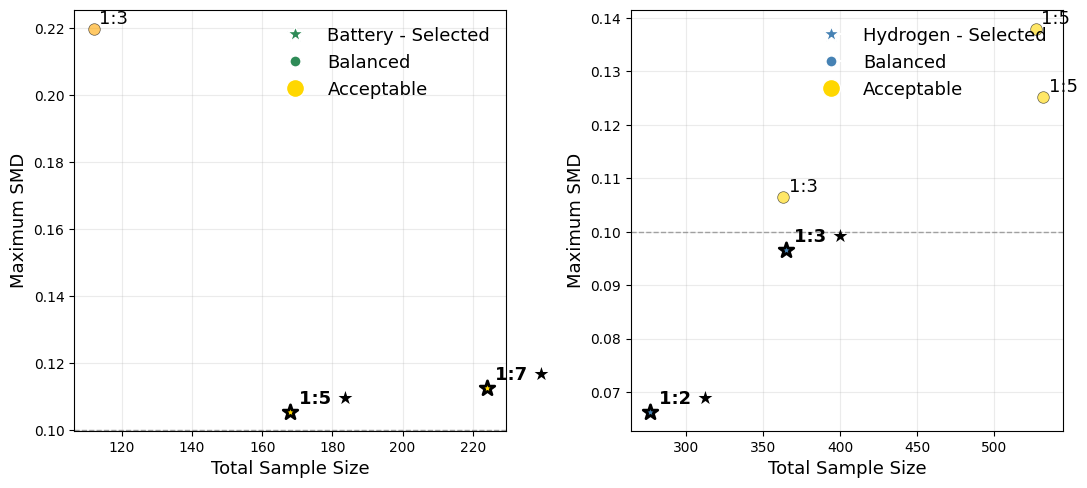

In [22]:
# ============================================================
# 3. Trade-off Plot (Both Specs Highlighted)
# ============================================================

def plot_tradeoff_combined(battery_results, hydrogen_results):

    fig, axes = plt.subplots(1, 2, figsize=(11, 5))

    def draw(ax, results, title, selected_specs):

        for spec_key, spec_data in results.items():

            total_n = spec_data["n_treated"] + spec_data["n_control"]
            max_smd = spec_data["max_smd"]

            is_selected = spec_key in selected_specs

            if max_smd <= 0.10:
                color = COLORS["two"][1] if "Battery" in title else COLORS["two"][0]
            elif max_smd <= 0.15:
                color = "#FFD700"
            else:
                color = "#FFA500"

            ax.scatter(total_n, max_smd,
                       color=color,
                       s=120 if is_selected else 70,
                       edgecolors="black",
                       linewidth=2 if is_selected else 0.5,
                       marker='*' if is_selected else 'o',
                       zorder=10 if is_selected else 5,
                       alpha=1.0 if is_selected else 0.6)

            label = f"1:{spec_data['ratio']}"
            if is_selected:
                label += " ★"

            ax.annotate(label, (total_n, max_smd),
                        xytext=(6 if is_selected else 4, 6 if is_selected else 4),
                        textcoords="offset points",
                        fontsize=13,
                        fontweight='bold' if is_selected else 'normal')

        ax.axhline(0.10, linestyle="--", color="gray", linewidth=1, alpha=0.7)

        ipcei_label = "Battery" if "Battery" in title else "Hydrogen"

        legend_elements = [
            Line2D([0],[0], marker='*', color='w',
                   markerfacecolor=(COLORS["two"][1] if "Battery" in title else COLORS["two"][0]),
                   markersize=12, label=f"{ipcei_label} - Selected"),
            Line2D([0],[0], marker='o', color='w',
                   markerfacecolor=(COLORS["two"][1] if "Battery" in title else COLORS["two"][0]),
                   markersize=8, label="Balanced"),
            Line2D([0],[0], marker='o', color='w',
                   markerfacecolor="#FFD700", markersize=13,
                   label="Acceptable"),
        ]

        ax.legend(handles=legend_elements, frameon=False, fontsize=13, loc="upper right")

        style_ax(ax)
        ax.set_xlabel("Total Sample Size", fontsize=13)
        ax.set_ylabel("Maximum SMD", fontsize=13)
        ax.grid(alpha=0.25)

    draw(axes[0], battery_results, "Battery IPCEI", ["battery_1to5", "battery_1to7"]) # HARDCODED HERE
    draw(axes[1], hydrogen_results, "Hydrogen IPCEI", ["hydrogen_cal20_r2", "hydrogen_cal25_r3"])

    plt.tight_layout()
    save_fig(fig, "descriptives_postmatch", "matching_tradeoff_bubbleplot")
    plt.show()

plot_tradeoff_combined(battery_results, hydrogen_results)

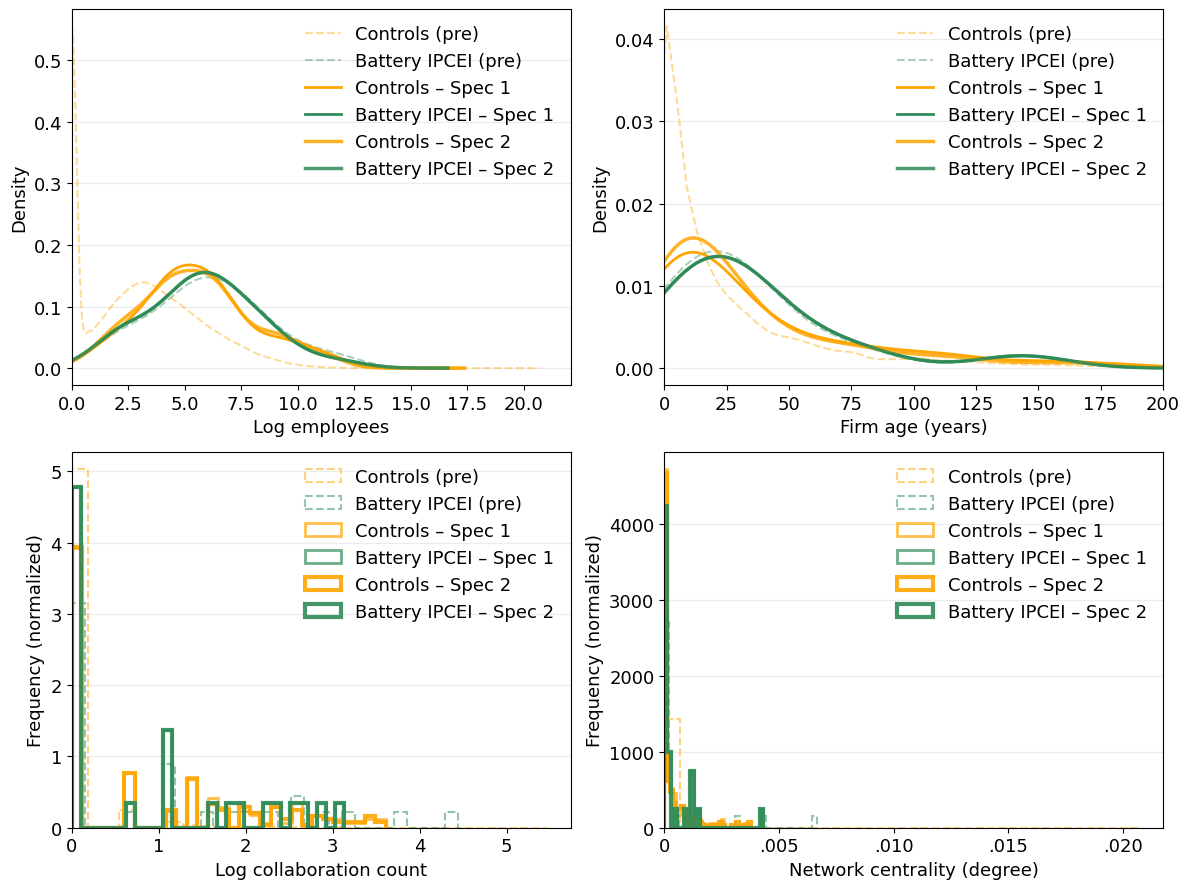

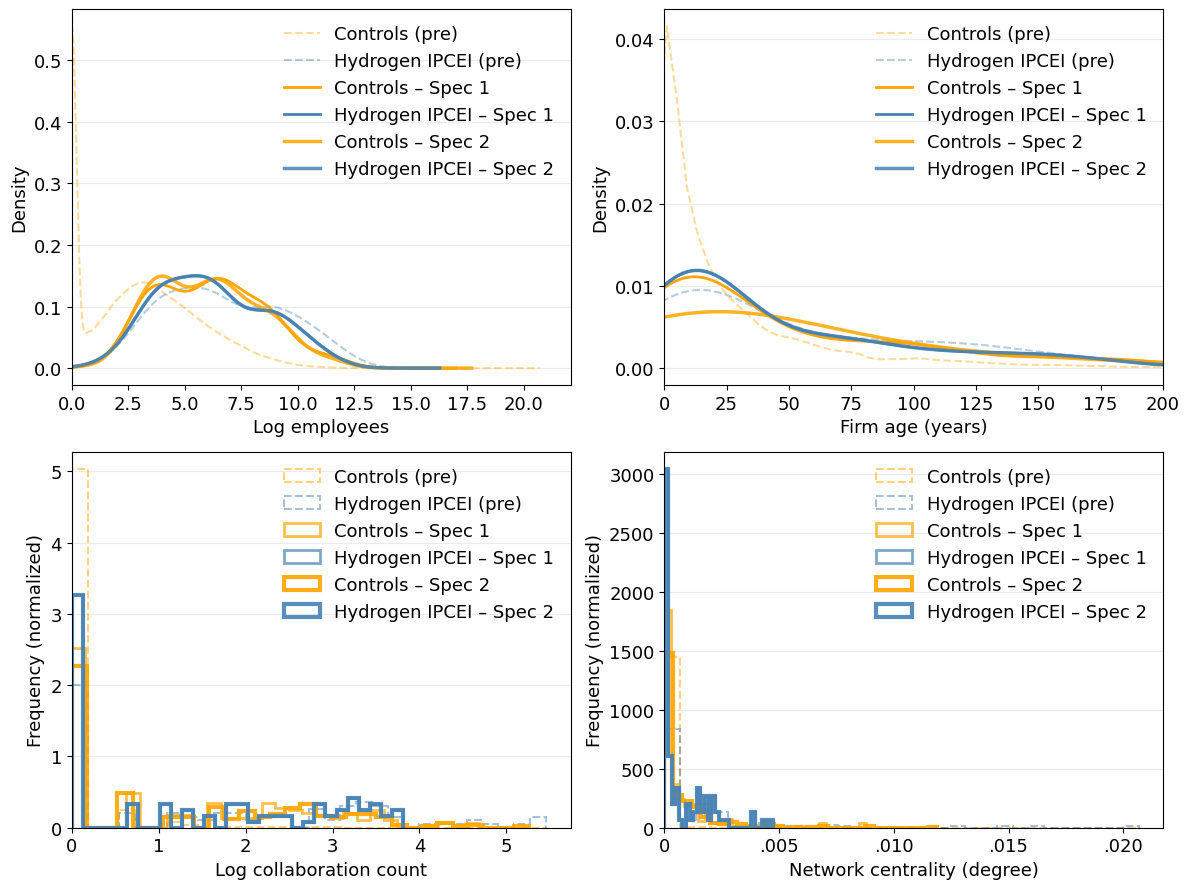


✅ Distribution plots created!


In [24]:
# ============================================================
# 4. Distribution Overlap (Spec 1 / Spec 2) - WITH HISTOGRAMS
# ============================================================

def plot_covariate_distributions(
    matched_spec1,
    matched_spec2,
    treatment_var,
    treatment_label,
    covariates,
    fm,
    mode="both"   # "spec1", "spec2", or "both"
):
    """
    Plot covariate distributions before and after matching.
    Uses histograms for sparse/skewed variables (collabs, centrality).
    Uses density plots for normal variables (size, age).
    """

    # Drop indicator-style covariates
    base_vars = [v for v in covariates if not v.startswith("is_")]

    # --- Validate treatment_var exists ---
    for name, df in [("fm", fm), ("matched_spec1", matched_spec1), ("matched_spec2", matched_spec2)]:
        if df is not None and treatment_var not in df.columns:
            raise KeyError(
                f"'{treatment_var}' not found in {name}. "
                f"Try using 'battery_ipcei' / 'hydrogen_ipcei' or create the indicator column."
            )

    # --- Validate covariates exist ---
    missing_fm = [v for v in base_vars if v not in fm.columns]
    if missing_fm:
        raise KeyError(f"These covariates are missing in fm: {missing_fm}")

    if matched_spec1 is not None:
        missing_s1 = [v for v in base_vars if v not in matched_spec1.columns]
        if missing_s1:
            raise KeyError(f"These covariates are missing in matched_spec1: {missing_s1}")

    if matched_spec2 is not None:
        missing_s2 = [v for v in base_vars if v not in matched_spec2.columns]
        if missing_s2:
            raise KeyError(f"These covariates are missing in matched_spec2: {missing_s2}")

    # Layout
    n_cols = 2
    n_rows = (len(base_vars) + 1) // 2
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 4.5 * n_rows))

    if n_rows == 1:
        axes = axes.reshape(1, -1)

    treat_color = COLORS["two"][0] if "hydrogen" in treatment_label.lower() else COLORS["two"][1]
    control_color = "#FFA500"

    for i, var in enumerate(base_vars):
        ax = axes[i // n_cols, i % n_cols]

        # --- Determine plot type based on variable ---
        use_histogram = any(x in var.lower() for x in ["collab", "centrality", "log_collab", "log_degree"])

        # --- Get data ---
        treated_full = fm.loc[fm[treatment_var] == 1, var].dropna()
        control_full = fm.loc[fm[treatment_var] == 0, var].dropna()

        if mode in ["spec1", "both"] and matched_spec1 is not None:
            treated_s1 = matched_spec1.loc[matched_spec1[treatment_var] == 1, var].dropna()
            control_s1 = matched_spec1.loc[matched_spec1[treatment_var] == 0, var].dropna()
        else:
            treated_s1 = control_s1 = None

        if mode in ["spec2", "both"] and matched_spec2 is not None:
            treated_s2 = matched_spec2.loc[matched_spec2[treatment_var] == 1, var].dropna()
            control_s2 = matched_spec2.loc[matched_spec2[treatment_var] == 0, var].dropna()
        else:
            treated_s2 = control_s2 = None

        # ============================================================
        # HISTOGRAM VERSION (for sparse variables)
        # ============================================================
        if use_histogram:

            bins = 30

            # Pre-match (dashed outline)
            ax.hist(control_full, bins=bins, density=True,
                   histtype='step', linestyle='--', linewidth=1.5,
                   alpha=0.5, color=control_color, label="Controls (pre)")
            ax.hist(treated_full, bins=bins, density=True,
                   histtype='step', linestyle='--', linewidth=1.5,
                   alpha=0.5, color=treat_color, label=f"{treatment_label} (pre)")

            # Spec 1 (solid thin line)
            if treated_s1 is not None and control_s1 is not None:
                ax.hist(control_s1, bins=bins, density=True,
                       histtype='step', linewidth=2, alpha=0.7,
                       color=control_color, label="Controls – Spec 1")
                ax.hist(treated_s1, bins=bins, density=True,
                       histtype='step', linewidth=2, alpha=0.7,
                       color=treat_color, label=f"{treatment_label} – Spec 1")

            # Spec 2 (solid thick line)
            if treated_s2 is not None and control_s2 is not None:
                ax.hist(control_s2, bins=bins, density=True,
                       histtype='step', linewidth=3, alpha=0.9,
                       color=control_color, label="Controls – Spec 2")
                ax.hist(treated_s2, bins=bins, density=True,
                       histtype='step', linewidth=3, alpha=0.9,
                       color=treat_color, label=f"{treatment_label} – Spec 2")

        # ============================================================
        # DENSITY VERSION (for normal variables)
        # ============================================================
        else:

            # Pre-match (dashed)
            control_full.plot(kind="density", ax=ax,
                            color=control_color, linestyle="--", alpha=0.4,
                            label="Controls (pre)")
            treated_full.plot(kind="density", ax=ax,
                            color=treat_color, linestyle="--", alpha=0.4,
                            label=f"{treatment_label} (pre)")

            # Spec 1 (solid thin)
            if treated_s1 is not None and control_s1 is not None:
                control_s1.plot(kind="density", ax=ax,
                               color=control_color, linewidth=2,
                               label="Controls – Spec 1")
                treated_s1.plot(kind="density", ax=ax,
                               color=treat_color, linewidth=2,
                               label=f"{treatment_label} – Spec 1")

            # Spec 2 (solid thick)
            if treated_s2 is not None and control_s2 is not None:
                control_s2.plot(kind="density", ax=ax,
                               color=control_color, linewidth=2.5, alpha=0.85,
                               label="Controls – Spec 2")
                treated_s2.plot(kind="density", ax=ax,
                               color=treat_color, linewidth=2.5, alpha=0.85,
                               label=f"{treatment_label} – Spec 2")

        # ============================================================
        # Styling
        # ============================================================

        # Nonnegative axis
        xmin, xmax = ax.get_xlim()
        if xmin < 0:
            ax.set_xlim(left=0)

        # Variable-specific caps
        if var == "age":
            ax.set_xlim(0, 200)

        ax.set_xlabel(VAR_LABELS.get(var, var), fontsize=13)
        ax.set_ylabel("Density" if not use_histogram else "Frequency (normalized)", fontsize=13)

        if "centrality" in var.lower():
            ax.set_xticks([0.000, 0.005, 0.010, 0.015, 0.020])
            ax.set_xticklabels(["0", ".005", ".010", ".015", ".020"])

        style_ax(ax)
        ax.tick_params(axis="both", labelsize=13)
        ax.legend(frameon=False, fontsize=13, loc='best')

    # Hide unused last panel if odd number of vars
    if len(base_vars) % 2 == 1:
        axes[-1, -1].axis("off")

    plt.tight_layout()

    # Determine spec suffix for filename
    spec_suffix = "spec1" if mode == "spec1" else "spec2" if mode == "spec2" else "both_specs"

    save_fig(
        fig,
        "descriptives_postmatch",
        f"matching_{treatment_label.lower().replace(' ', '_')}_distributions_{spec_suffix}"
    )

    plt.show()


# ============================================================
# Plot for both technologies
# ============================================================

# Battery - add treatment indicator
battery_spec1["is_battery_treated"] = (
    battery_spec1["ipcei_types"].astype(str).str.lower().str.contains("battery", na=False)
).astype(int)

battery_spec2["is_battery_treated"] = (
    battery_spec2["ipcei_types"].astype(str).str.lower().str.contains("battery", na=False)
).astype(int)

# Hydrogen - add treatment indicator
hydrogen_spec1["is_hydrogen_treated"] = (
    hydrogen_spec1["ipcei_types"].astype(str).str.lower().str.contains("hydrogen", na=False)
).astype(int)

hydrogen_spec2["is_hydrogen_treated"] = (
    hydrogen_spec2["ipcei_types"].astype(str).str.lower().str.contains("hydrogen", na=False)
).astype(int)

# Add to fm as well
fm["is_battery_treated"] = (
    fm["ipcei_types"].astype(str).str.lower().str.contains("battery", na=False)
).astype(int)

fm["is_hydrogen_treated"] = (
    fm["ipcei_types"].astype(str).str.lower().str.contains("hydrogen", na=False)
).astype(int)

# Plot Battery
plot_covariate_distributions(
    battery_spec1, battery_spec2,
    "is_battery_treated", "Battery IPCEI",
    battery_continuous_vars, fm, mode="both"
)

# Plot Hydrogen
plot_covariate_distributions(
    hydrogen_spec1, hydrogen_spec2,
    "is_hydrogen_treated", "Hydrogen IPCEI",
    hydrogen_continuous_vars, fm, mode="both"
)

print("\n✅ Distribution plots created!")


DiD DIAGNOSTIC PLOTS:

Battery Spec 1 plot panel: 4200 obs, 168 firms
Hydrogen Spec 1 plot panel: 6925 obs, 269 firms

Battery Spec 2 plot panel: 5600 obs, 224 firms
Hydrogen Spec 2 plot panel: 9125 obs, 349 firms


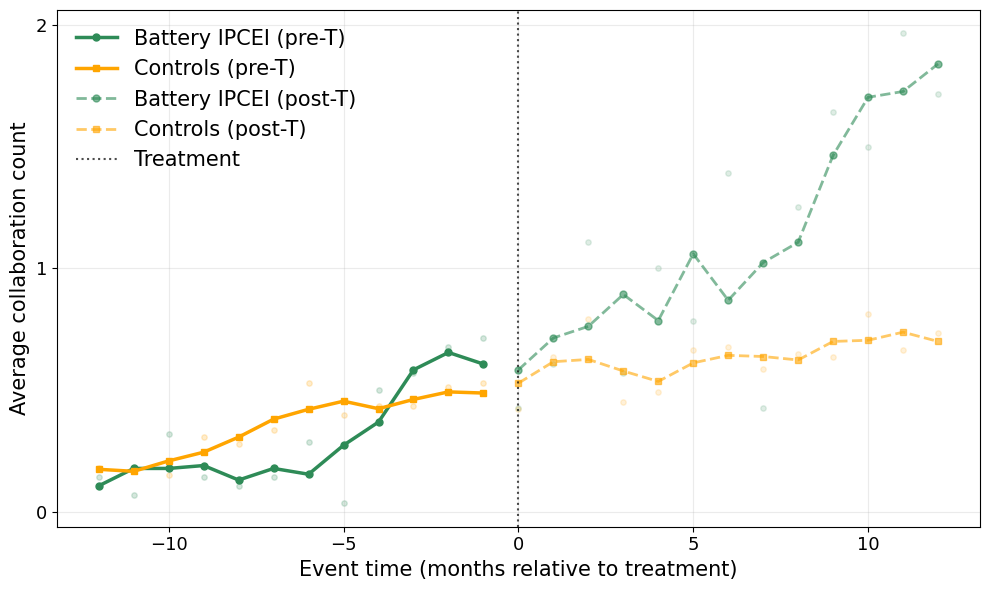

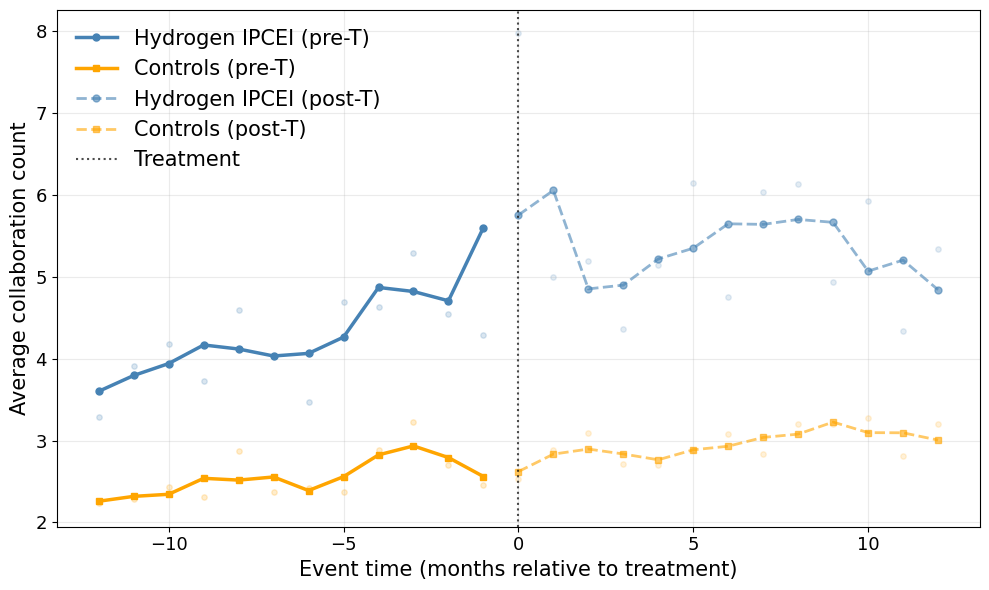

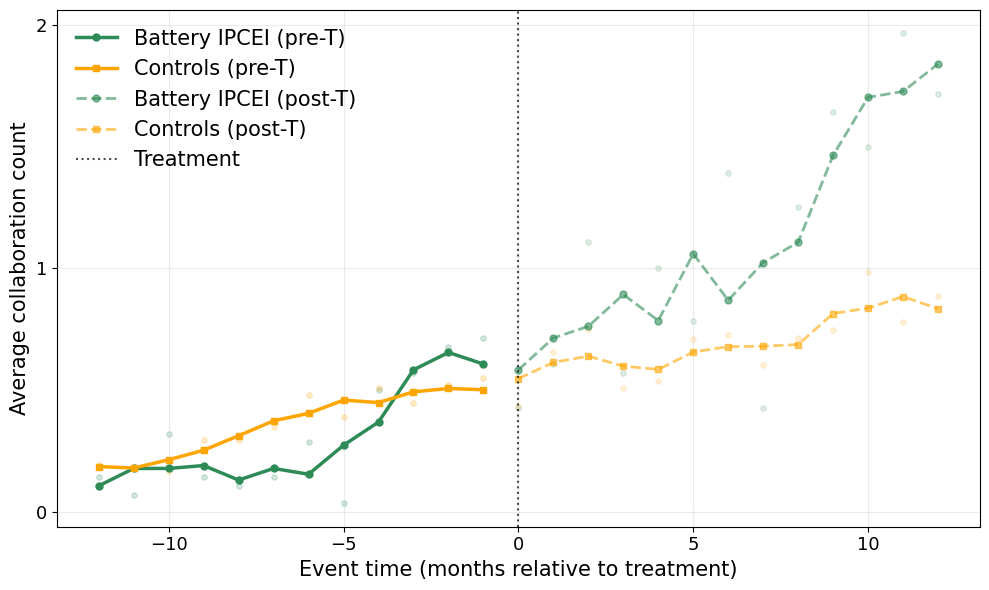

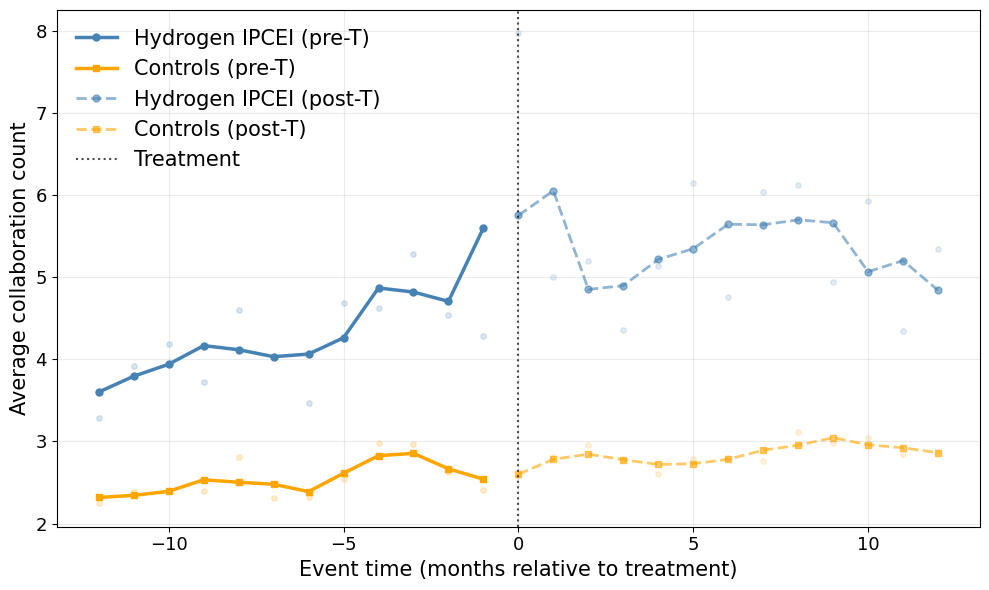


✅ Pre-trends plots created!


In [38]:
# ============================================================
# DiD Diagnostic Plots
# ============================================================

print("\nDiD DIAGNOSTIC PLOTS:")

# ============================================================
# Load Plot Panels (Spec 1 - Balance, Spec 2 - Power)
# ============================================================

battery_plot_spec1 = load_df("processed", "combined", "battery_spec1_plot_panel.csv")
hydrogen_plot_spec1 = load_df("processed", "combined", "hydrogen_spec1_plot_panel.csv")

battery_plot_spec2 = load_df("processed", "combined", "battery_spec2_plot_panel.csv")
hydrogen_plot_spec2 = load_df("processed", "combined", "hydrogen_spec2_plot_panel.csv")

print(f"\nBattery Spec 1 plot panel: {len(battery_plot_spec1)} obs, {battery_plot_spec1['Linkedin_name'].nunique()} firms")
print(f"Hydrogen Spec 1 plot panel: {len(hydrogen_plot_spec1)} obs, {hydrogen_plot_spec1['Linkedin_name'].nunique()} firms")

print(f"\nBattery Spec 2 plot panel: {len(battery_plot_spec2)} obs, {battery_plot_spec2['Linkedin_name'].nunique()} firms")
print(f"Hydrogen Spec 2 plot panel: {len(hydrogen_plot_spec2)} obs, {hydrogen_plot_spec2['Linkedin_name'].nunique()} firms")

# ============================================================
# Pre-trends Plot (3-month rolling average)
# ============================================================

def plot_pretrends_smoothed(panel_data, tech_label, treat_color, control_color, spec_type, window=3):
    """
    Plot average outcome over event time with rolling average smoothing.

    spec_type: "balance" or "power"
    """

    # Separate treated and controls
    treated = panel_data[panel_data["is_treated"] == 1].copy()
    controls = panel_data[panel_data["is_control"] == 1].copy()

    if len(treated) == 0:
        print(f"⚠️ No treated firms in {tech_label} panel")
        return

    # Aggregate by event_time_aligned
    treated_trend = treated.groupby("event_time_aligned")["n_collabs"].mean().reset_index()
    controls_trend = controls.groupby("event_time_aligned")["n_collabs"].mean().reset_index()

    # Apply rolling average
    treated_trend = treated_trend.sort_values("event_time_aligned")
    controls_trend = controls_trend.sort_values("event_time_aligned")

    treated_trend["n_collabs_smooth"] = treated_trend["n_collabs"].rolling(
        window=window, center=True, min_periods=1
    ).mean()

    controls_trend["n_collabs_smooth"] = controls_trend["n_collabs"].rolling(
        window=window, center=True, min_periods=1
    ).mean()

    # Plot
    fig, ax = plt.subplots(figsize=(10, 6))

    # Pre-treatment periods
    pre_treated = treated_trend[treated_trend["event_time_aligned"] < 0]
    pre_controls = controls_trend[controls_trend["event_time_aligned"] < 0]

    # Post-treatment periods
    post_treated = treated_trend[treated_trend["event_time_aligned"] >= 0]
    post_controls = controls_trend[controls_trend["event_time_aligned"] >= 0]

    # Pre-treatment (solid lines) - SMOOTHED
    ax.plot(pre_treated["event_time_aligned"], pre_treated["n_collabs_smooth"],
            color=treat_color, linewidth=2.5, marker='o', markersize=5,
            label=f"{tech_label} (pre-T)")

    # Add raw data as faint dots
    ax.scatter(pre_treated["event_time_aligned"], pre_treated["n_collabs"],
               color=treat_color, s=15, alpha=0.2)

    ax.plot(pre_controls["event_time_aligned"], pre_controls["n_collabs_smooth"],
            color=control_color, linewidth=2.5, marker='s', markersize=5,
            label="Controls (pre-T)")

    ax.scatter(pre_controls["event_time_aligned"], pre_controls["n_collabs"],
               color=control_color, s=15, alpha=0.2)

    # Post-treatment (dashed) - SMOOTHED
    ax.plot(post_treated["event_time_aligned"], post_treated["n_collabs_smooth"],
            color=treat_color, linewidth=2, marker='o', markersize=5,
            linestyle='--', alpha=0.6, label=f"{tech_label} (post-T)")

    ax.scatter(post_treated["event_time_aligned"], post_treated["n_collabs"],
               color=treat_color, s=15, alpha=0.15)

    ax.plot(post_controls["event_time_aligned"], post_controls["n_collabs_smooth"],
            color=control_color, linewidth=2, marker='s', markersize=5,
            linestyle='--', alpha=0.6, label="Controls (post-T)")

    ax.scatter(post_controls["event_time_aligned"], post_controls["n_collabs"],
               color=control_color, s=15, alpha=0.15)

    # Treatment line
    ax.axvline(0, color='black', linestyle=':', linewidth=1.5, alpha=0.7,
               label='Treatment')

    ax.set_xlabel("Event time (months relative to treatment)", fontsize=15)
    ax.set_ylabel("Average collaboration count", fontsize=15)
    ax.tick_params(axis="both", labelsize=15)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))

    ax.legend(frameon=False, loc='upper left', fontsize=15)
    ax.tick_params(axis="both", labelsize=13)
    ax.grid(alpha=0.25)
    style_ax(ax)

    plt.tight_layout()
    save_fig(fig, "descriptives_postmatch",
             f"did_{tech_label.lower().replace(' ', '_')}_pretrends_{spec_type}")
    plt.show()

# ============================================================
# Plot Spec 1 (Balance)
# ============================================================

plot_pretrends_smoothed(battery_plot_spec1, "Battery IPCEI", COLORS["two"][1], "#FFA500", "balance", window=3)
plot_pretrends_smoothed(hydrogen_plot_spec1, "Hydrogen IPCEI", COLORS["two"][0], "#FFA500", "balance", window=3)

# ============================================================
# Plot Spec 2 (Power)
# ============================================================

plot_pretrends_smoothed(battery_plot_spec2, "Battery IPCEI", COLORS["two"][1], "#FFA500", "power", window=3)
plot_pretrends_smoothed(hydrogen_plot_spec2, "Hydrogen IPCEI", COLORS["two"][0], "#FFA500", "power", window=3)

print("\n✅ Pre-trends plots created!")

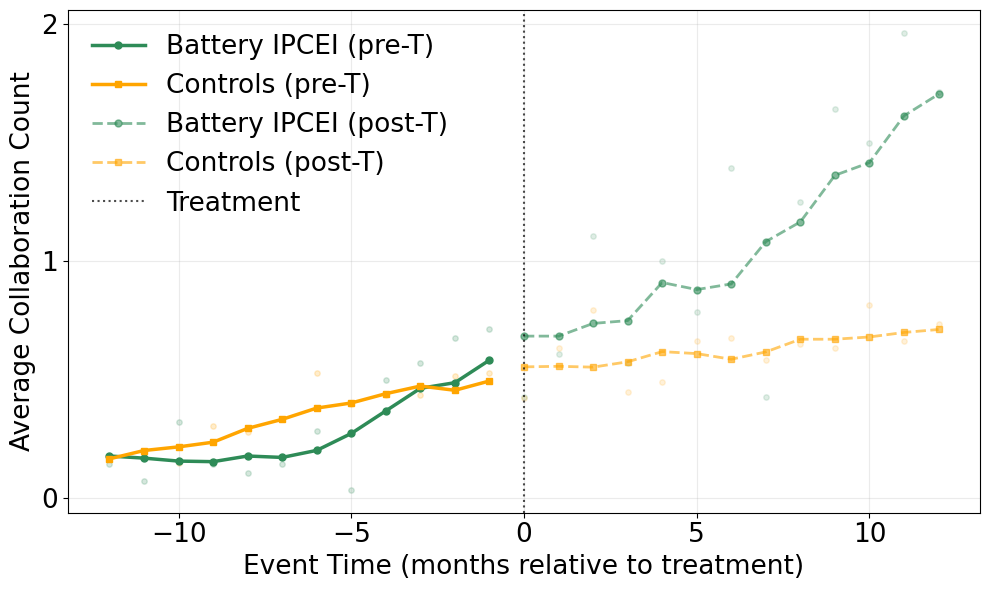

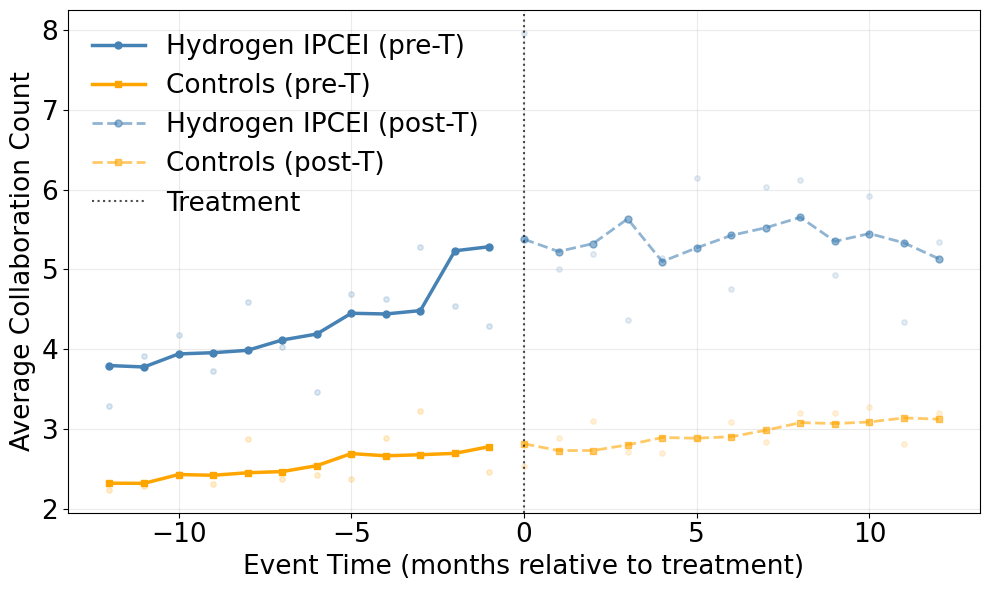

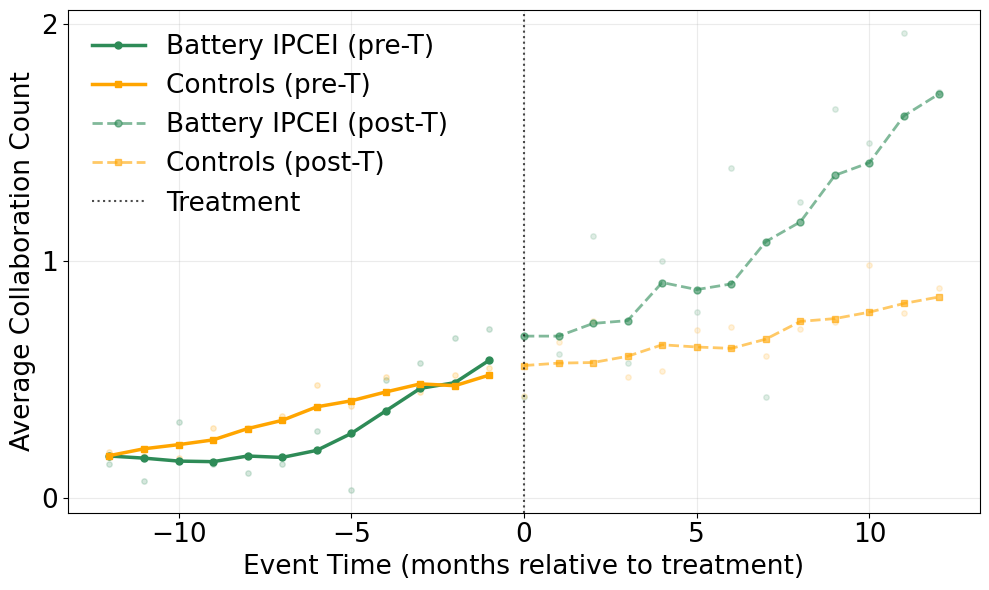

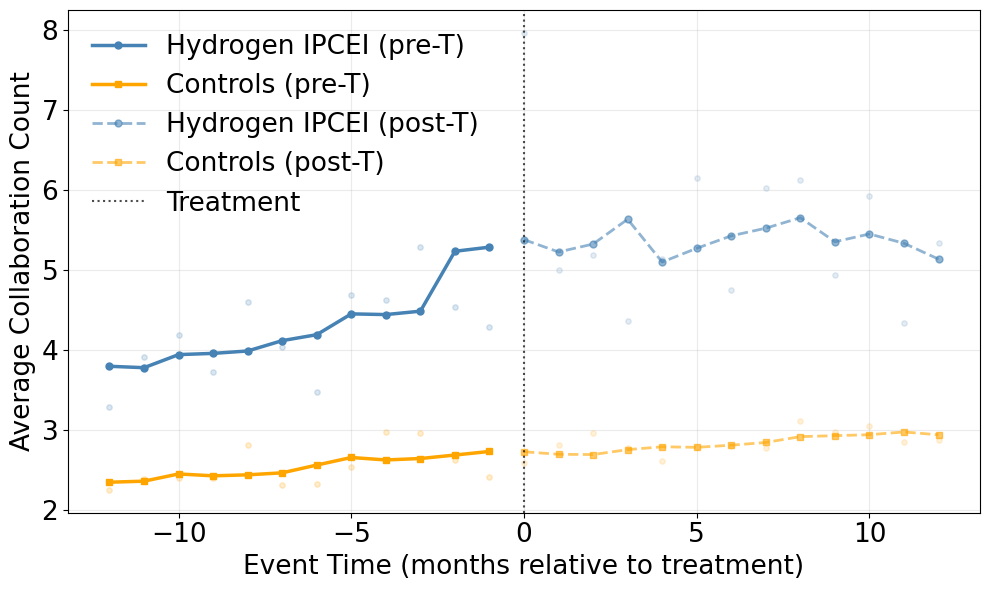


✅ 6-month smoothed pre-trends plots created!


In [37]:
# ============================================================
# DiD Pre-trends - 6-Month Smoothing (Main Specification)
# ============================================================

def plot_pretrends_smoothed_6m(panel_data, tech_label, treat_color, control_color, spec_type):
    """
    Plot average outcome over event time with 6-month rolling average smoothing.
    Cleaner trends for main paper.
    """

    # Separate treated and controls
    treated = panel_data[panel_data["is_treated"] == 1].copy()
    controls = panel_data[panel_data["is_control"] == 1].copy()

    if len(treated) == 0:
        print(f"⚠️ No treated firms in {tech_label} panel")
        return

    # Aggregate by event_time_aligned
    treated_trend = treated.groupby("event_time_aligned")["n_collabs"].mean().reset_index()
    controls_trend = controls.groupby("event_time_aligned")["n_collabs"].mean().reset_index()

    # Apply 6-month rolling average
    treated_trend = treated_trend.sort_values("event_time_aligned")
    controls_trend = controls_trend.sort_values("event_time_aligned")

    treated_trend["n_collabs_smooth"] = treated_trend["n_collabs"].rolling(
        window=6, center=True, min_periods=1
    ).mean()

    controls_trend["n_collabs_smooth"] = controls_trend["n_collabs"].rolling(
        window=6, center=True, min_periods=1
    ).mean()

    # Plot
    fig, ax = plt.subplots(figsize=(10, 6))

    # Pre-treatment periods
    pre_treated = treated_trend[treated_trend["event_time_aligned"] < 0]
    pre_controls = controls_trend[controls_trend["event_time_aligned"] < 0]

    # Post-treatment periods
    post_treated = treated_trend[treated_trend["event_time_aligned"] >= 0]
    post_controls = controls_trend[controls_trend["event_time_aligned"] >= 0]

    # Pre-treatment (solid lines) - SMOOTHED
    ax.plot(pre_treated["event_time_aligned"], pre_treated["n_collabs_smooth"],
            color=treat_color, linewidth=2.5, marker='o', markersize=5,
            label=f"{tech_label} (pre-T)")

    # Add raw data as faint dots
    ax.scatter(pre_treated["event_time_aligned"], pre_treated["n_collabs"],
               color=treat_color, s=15, alpha=0.2)

    ax.plot(pre_controls["event_time_aligned"], pre_controls["n_collabs_smooth"],
            color=control_color, linewidth=2.5, marker='s', markersize=5,
            label="Controls (pre-T)")

    ax.scatter(pre_controls["event_time_aligned"], pre_controls["n_collabs"],
               color=control_color, s=15, alpha=0.2)

    # Post-treatment (dashed) - SMOOTHED
    ax.plot(post_treated["event_time_aligned"], post_treated["n_collabs_smooth"],
            color=treat_color, linewidth=2, marker='o', markersize=5,
            linestyle='--', alpha=0.6, label=f"{tech_label} (post-T)")

    ax.scatter(post_treated["event_time_aligned"], post_treated["n_collabs"],
               color=treat_color, s=15, alpha=0.15)

    ax.plot(post_controls["event_time_aligned"], post_controls["n_collabs_smooth"],
            color=control_color, linewidth=2, marker='s', markersize=5,
            linestyle='--', alpha=0.6, label="Controls (post-T)")

    ax.scatter(post_controls["event_time_aligned"], post_controls["n_collabs"],
               color=control_color, s=15, alpha=0.15)

    # Treatment line
    ax.axvline(0, color='black', linestyle=':', linewidth=1.5, alpha=0.7,
               label='Treatment')

    ax.set_xlabel("Event Time (months relative to treatment)", fontsize=19)
    ax.set_ylabel("Average Collaboration Count", fontsize=19)
    ax.tick_params(axis="both", labelsize=19)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))

    ax.legend(frameon=False, loc='upper left', fontsize=19)
    ax.grid(alpha=0.25)
    style_ax(ax)

    plt.tight_layout()
    save_fig(fig, "descriptives_postmatch",
             f"did_{tech_label.lower().replace(' ', '_')}_pretrends_{spec_type}_6m")
    plt.show()

# Plot 6-month smoothing for Spec 1 (Balance)
plot_pretrends_smoothed_6m(battery_plot_spec1, "Battery IPCEI", COLORS["two"][1], "#FFA500", "balance")
plot_pretrends_smoothed_6m(hydrogen_plot_spec1, "Hydrogen IPCEI", COLORS["two"][0], "#FFA500", "balance")

# Plot 6-month smoothing for Spec 2 (Power)
plot_pretrends_smoothed_6m(battery_plot_spec2, "Battery IPCEI", COLORS["two"][1], "#FFA500", "power")
plot_pretrends_smoothed_6m(hydrogen_plot_spec2, "Hydrogen IPCEI", COLORS["two"][0], "#FFA500", "power")

print("\n✅ 6-month smoothed pre-trends plots created!")

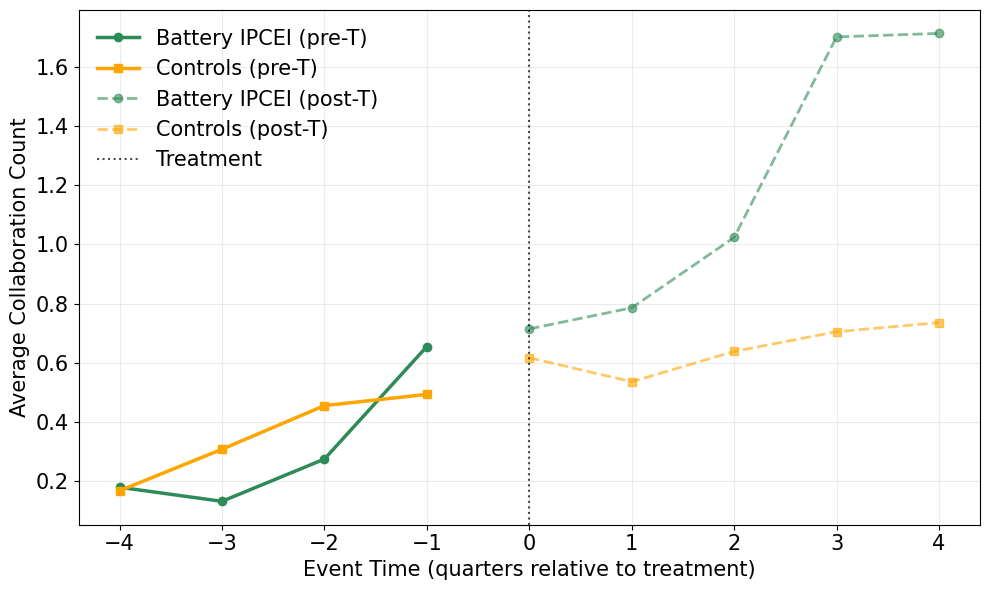

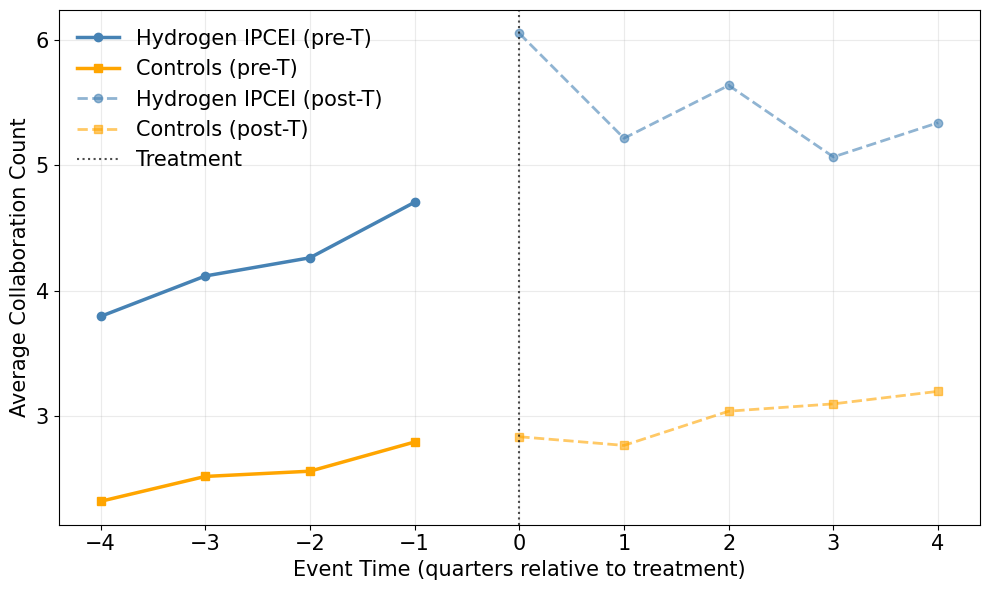

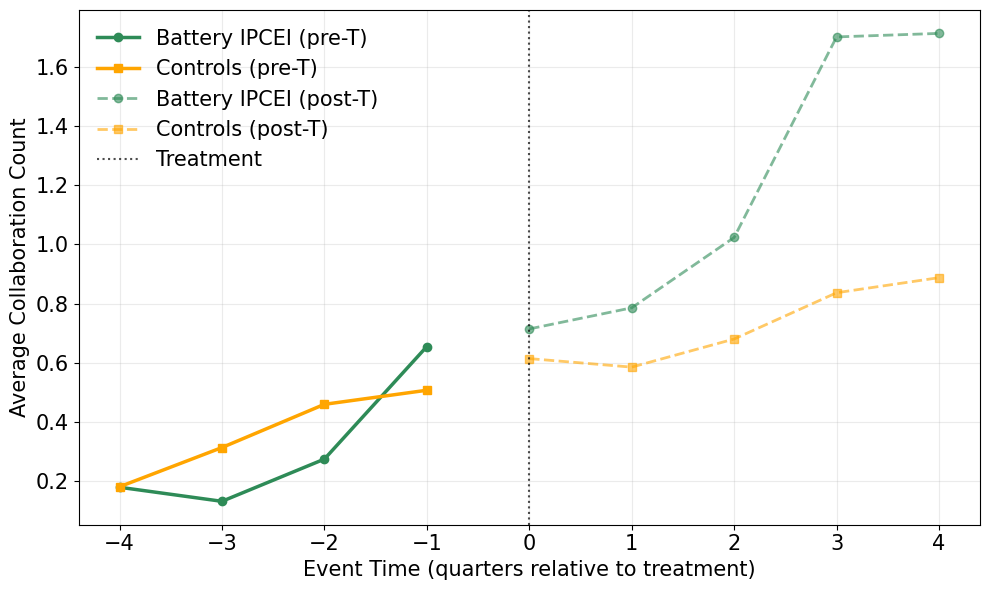

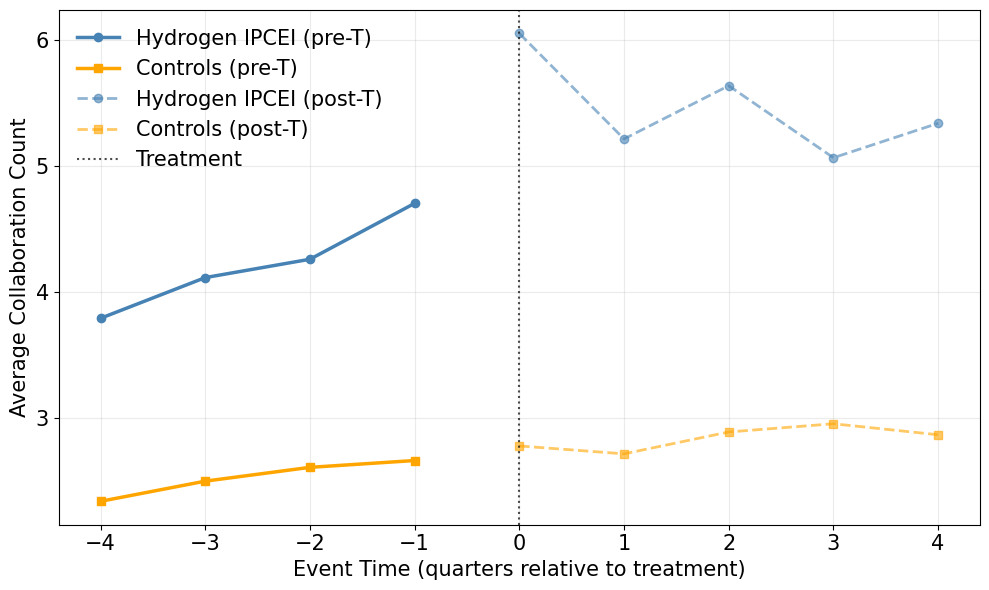


✅ Quarterly pre-trends plots created!


In [39]:
# ============================================================
# DiD Pre-trends - Quarterly Aggregation (Robustness)
# ============================================================

def plot_pretrends_quarterly(panel_data, tech_label, treat_color, control_color, spec_type):
    """
    Aggregate to quarters instead of smoothing months.
    Transparent aggregation with no arbitrary smoothing choices.
    """

    treated = panel_data[panel_data["is_treated"] == 1].copy()
    controls = panel_data[panel_data["is_control"] == 1].copy()

    if len(treated) == 0:
        print(f"⚠️ No treated firms in {tech_label} panel")
        return

    # Create quarter variable (every 3 months)
    treated["quarter"] = (treated["event_time_aligned"] // 3).astype(int)
    controls["quarter"] = (controls["event_time_aligned"] // 3).astype(int)

    # Aggregate to quarters
    treated_trend = treated.groupby("quarter")["n_collabs"].mean().reset_index()
    controls_trend = controls.groupby("quarter")["n_collabs"].mean().reset_index()

    # Plot
    fig, ax = plt.subplots(figsize=(10, 6))

    # Pre-treatment quarters
    pre_treated = treated_trend[treated_trend["quarter"] < 0]
    pre_controls = controls_trend[controls_trend["quarter"] < 0]

    # Post-treatment quarters
    post_treated = treated_trend[treated_trend["quarter"] >= 0]
    post_controls = controls_trend[controls_trend["quarter"] >= 0]

    # Pre-treatment (solid lines)
    ax.plot(pre_treated["quarter"], pre_treated["n_collabs"],
            color=treat_color, linewidth=2.5, marker='o', markersize=6,
            label=f"{tech_label} (pre-T)")

    ax.plot(pre_controls["quarter"], pre_controls["n_collabs"],
            color=control_color, linewidth=2.5, marker='s', markersize=6,
            label="Controls (pre-T)")

    # Post-treatment (dashed)
    ax.plot(post_treated["quarter"], post_treated["n_collabs"],
            color=treat_color, linewidth=2, marker='o', markersize=6,
            linestyle='--', alpha=0.6, label=f"{tech_label} (post-T)")

    ax.plot(post_controls["quarter"], post_controls["n_collabs"],
            color=control_color, linewidth=2, marker='s', markersize=6,
            linestyle='--', alpha=0.6, label="Controls (post-T)")

    # Treatment line
    ax.axvline(0, color='black', linestyle=':', linewidth=1.5, alpha=0.7,
               label='Treatment')

    ax.set_xlabel("Event Time (quarters relative to treatment)", fontsize=15)
    ax.set_ylabel("Average Collaboration Count", fontsize=15)
    ax.tick_params(axis="both", labelsize=15)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))

    ax.legend(frameon=False, loc='upper left', fontsize=15)
    ax.grid(alpha=0.25)
    style_ax(ax)

    plt.tight_layout()
    save_fig(fig, "descriptives_postmatch",
             f"did_{tech_label.lower().replace(' ', '_')}_pretrends_{spec_type}_quarterly")
    plt.show()

# Plot quarterly for Spec 1 (Balance)
plot_pretrends_quarterly(battery_plot_spec1, "Battery IPCEI", COLORS["two"][1], "#FFA500", "balance")
plot_pretrends_quarterly(hydrogen_plot_spec1, "Hydrogen IPCEI", COLORS["two"][0], "#FFA500", "balance")

# Plot quarterly for Spec 2 (Power)
plot_pretrends_quarterly(battery_plot_spec2, "Battery IPCEI", COLORS["two"][1], "#FFA500", "power")
plot_pretrends_quarterly(hydrogen_plot_spec2, "Hydrogen IPCEI", COLORS["two"][0], "#FFA500", "power")

print("\n✅ Quarterly pre-trends plots created!")

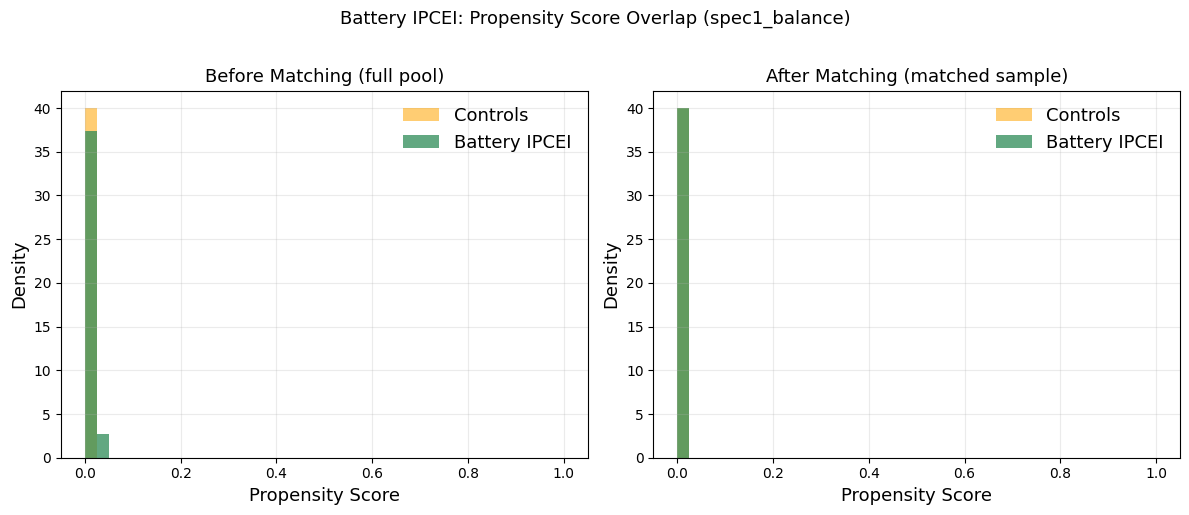

✅ PSM overlap plot done: Battery IPCEI spec1_balance


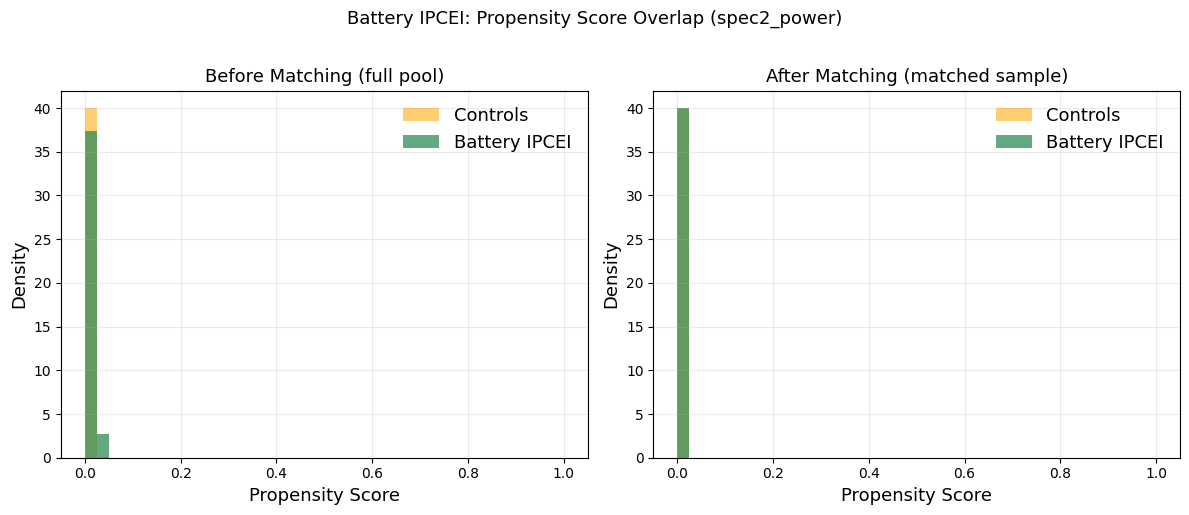

✅ PSM overlap plot done: Battery IPCEI spec2_power


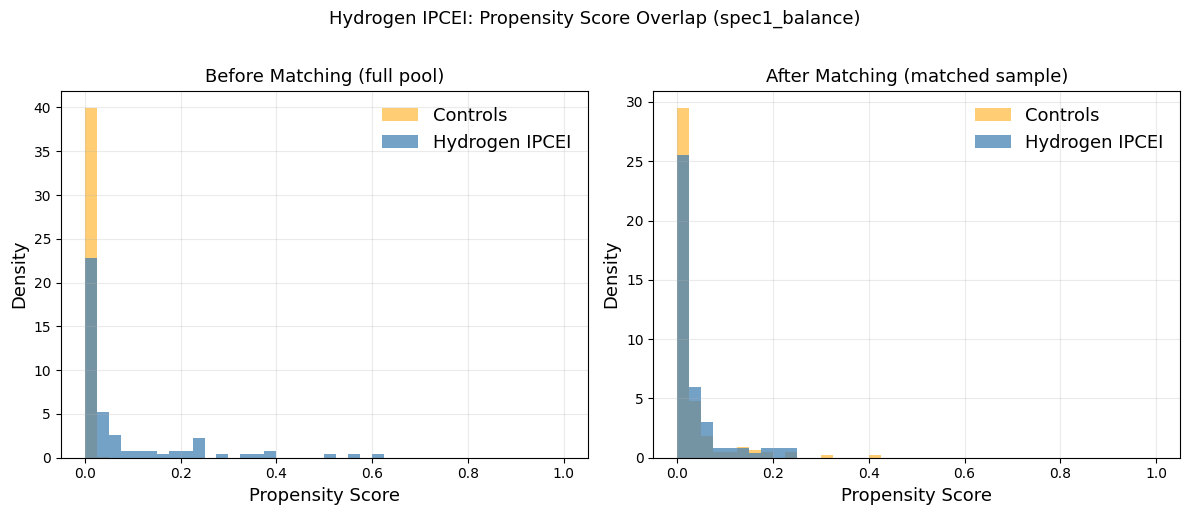

✅ PSM overlap plot done: Hydrogen IPCEI spec1_balance


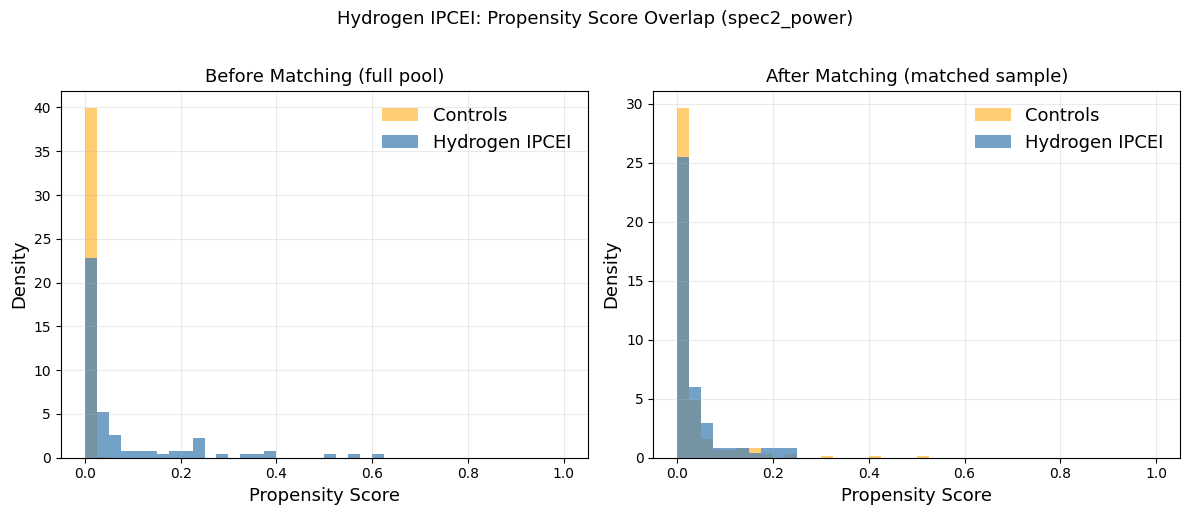

✅ PSM overlap plot done: Hydrogen IPCEI spec2_power


In [30]:
# ============================================================
# Propensity Score Overlap Plot — standalone, robust version
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

def plot_propensity_overlap(
    fm,
    matched_data,
    treatment_var,
    continuous_vars,
    exact_match_vars,
    tech_label,
    spec_label,
    treat_color,
    save_dir="descriptives_postmatch"
):
    """
    Propensity score overlap plot before and after matching.
    Uses logistic regression on continuous + dummy-encoded exact vars.
    """

    # ── 1. Build feature matrix on the FULL pre-match pool ───────────────
    df_model = fm.copy()

    # One-hot encode exact match vars
    df_encoded = pd.get_dummies(
        df_model[continuous_vars + exact_match_vars + [treatment_var, "Linkedin_name"]],
        columns=exact_match_vars,
        drop_first=True,
        dtype=float
    ).dropna()

    feature_cols = [c for c in df_encoded.columns
                    if c not in [treatment_var, "Linkedin_name"]]

    X = df_encoded[feature_cols].values
    y = df_encoded[treatment_var].values

    # Scale for logit stability
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    lr = LogisticRegression(max_iter=2000, C=1.0, random_state=42)
    lr.fit(X_scaled, y)

    df_encoded["pscore"] = lr.predict_proba(X_scaled)[:, 1]

    # ── 2. Flag which rows are in matched sample ──────────────────────────
    matched_names = set(matched_data["Linkedin_name"].dropna())
    df_encoded["in_matched"] = df_encoded["Linkedin_name"].isin(matched_names)

    pre_treated  = df_encoded[df_encoded[treatment_var] == 1]
    pre_control  = df_encoded[df_encoded[treatment_var] == 0]
    post_treated = df_encoded[df_encoded["in_matched"] & (df_encoded[treatment_var] == 1)]
    post_control = df_encoded[df_encoded["in_matched"] & (df_encoded[treatment_var] == 0)]

    # Guard: if empty after filtering, warn and return
    for name, subset in [("post_treated", post_treated),
                          ("post_control", post_control)]:
        if len(subset) == 0:
            print(f"⚠️  {name} is empty for {tech_label} — check Linkedin_name merge")
            return

    # ── 3. Plot ───────────────────────────────────────────────────────────
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=False)

    panels = [
        (pre_treated,  pre_control,  "Before Matching (full pool)"),
        (post_treated, post_control, "After Matching (matched sample)"),
    ]

    for ax, (treated_df, control_df, title) in zip(axes, panels):
        bins = np.linspace(0, 1, 41)

        ax.hist(control_df["pscore"], bins=bins, alpha=0.55,
                color="#FFA500", density=True, label="Controls")
        ax.hist(treated_df["pscore"], bins=bins, alpha=0.75,
                color=treat_color, density=True, label=tech_label)

        ax.set_xlabel("Propensity Score", fontsize=13)
        ax.set_ylabel("Density", fontsize=13)
        ax.legend(frameon=False, fontsize=13)
        ax.grid(alpha=0.25)
        style_ax(ax)
        ax.set_title(title, fontsize=13)

    fig.suptitle(
        f"{tech_label}: Propensity Score Overlap ({spec_label})",
        fontsize=13, y=1.02
    )
    plt.tight_layout()

    # ── 4. Save — uses your save_fig if available, else manual ───────────
    try:
        save_fig(fig, save_dir,
                 f"pscore_overlap_{tech_label.lower().replace(' ', '_')}_{spec_label}")
    except Exception as e:
        print(f"save_fig failed ({e}), saving manually")
        fname = f"{tech_label.lower().replace(' ', '_')}_{spec_label}_pscore_overlap.pdf"
        fig.savefig(fname, bbox_inches="tight")
        print(f"Saved to: {fname}")

    plt.show()
    plt.close(fig)  # prevent display issues in notebooks
    print(f"✅ PSM overlap plot done: {tech_label} {spec_label}")


# ── Call for both treatment groups and specs ──────────────────────────────────

plot_propensity_overlap(
    fm            = fm,
    matched_data  = battery_spec1,   # your matched df
    treatment_var = "battery_ipcei",
    continuous_vars   = battery_continuous_vars,
    exact_match_vars  = exact_match_vars,
    tech_label    = "Battery IPCEI",
    spec_label    = "spec1_balance",
    treat_color   = COLORS["two"][1]
)

plot_propensity_overlap(
    fm            = fm,
    matched_data  = battery_spec2,
    treatment_var = "battery_ipcei",
    continuous_vars   = battery_continuous_vars,
    exact_match_vars  = exact_match_vars,
    tech_label    = "Battery IPCEI",
    spec_label    = "spec2_power",
    treat_color   = COLORS["two"][1]
)

plot_propensity_overlap(
    fm            = fm,
    matched_data  = hydrogen_spec1,
    treatment_var = "hydrogen_ipcei",
    continuous_vars   = hydrogen_continuous_vars,
    exact_match_vars  = exact_match_vars,
    tech_label    = "Hydrogen IPCEI",
    spec_label    = "spec1_balance",
    treat_color   = COLORS["two"][0]
)

plot_propensity_overlap(
    fm            = fm,
    matched_data  = hydrogen_spec2,
    treatment_var = "hydrogen_ipcei",
    continuous_vars   = hydrogen_continuous_vars,
    exact_match_vars  = exact_match_vars,
    tech_label    = "Hydrogen IPCEI",
    spec_label    = "spec2_power",
    treat_color   = COLORS["two"][0]
)